# Predicción de readmisión hospitalaria a 30 días en pacientes con cáncer

## 1. Introducción y objetivo

Las readmisiones hospitalarias representan un problema relevante para la atención de pacientes oncológicos, debido a las complicaciones clínicas y la utilización de recursos sanitarios.

**Pregunta de investigación:**

¿El historial clínico de los 180 días previos al ingreso hospitalario mejora la predicción de readmisión a 30 días en adultos con cáncer, más allá de las hospitalizaciones previas?

**Objetivo:** desarrollar y comparar modelos predictivos utilizando datos clínicos sintéticos de Synthea, organizados mediante DuckDB y una estructura OMOP mínima.

**Diseño del estudio:**
- **Población:** adultos con cáncer confirmado.
- **Fecha índice:** ingreso hospitalario.
- **Predictores:** información disponible durante los 180 días anteriores al ingreso.
- **Desenlace:** nueva hospitalización dentro de los 30 días posteriores al egreso.
- **Enfoque:** aprendizaje automático supervisado para clasificación binaria.

El análisis prioriza la reproducibilidad, la interpretación clínica y la prevención de fugas de información.

**Cuatro configuraciones principales de la versión 2.3**

| Modelo | Algoritmo | Predictores |
|---|---|---:|
| M0 | Regresión logística | 3 |
| M1 | Regresión logística | 6 |
| M2 | XGBoost | 6, exactamente los de M1 |
| M2 + FE | XGBoost | 9 |

DummyClassifier se conserva como referencia estadística. M1 frente a M2 aísla el algoritmo; M2 frente a M2 + FE aísla las tres características adicionales. No se realiza búsqueda de hiperparámetros ni se evalúa la prueba temporal.


## 2. Carga del conjunto de datos

La cohorte original tiene 824 pacientes. Se carga únicamente el entrenamiento temporal: **655 pacientes y 76 eventos**. La fecha de corte **2022-11-27 07:16:42** procede de la partición ya documentada en 2.2 y permanece fija.

Las estadísticas y gráficas ejecutables describen entrenamiento. Los 165 pacientes de prueba no se cargan. Cuatro pacientes del bloque antiguo se excluyen por solapamiento del seguimiento. No se modifican la cohorte, el desenlace ni las bases.


In [2]:
from pathlib import Path
from importlib.metadata import version
import sys
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import mannwhitneyu, fisher_exact
from statsmodels.stats.multitest import multipletests
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate,
    cross_val_predict,
)
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    fbeta_score,
)
from xgboost import XGBClassifier, __version__ as xgboost_version

raiz = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "final_project/notebooks").is_dir()
    ),
    None,
)
if raiz is None:
    raise FileNotFoundError("Ejecuta el notebook dentro del repositorio.")
db_path = raiz / "final_project/data/omop_minimal.duckdb"
fecha_corte = pd.Timestamp("2022-11-27 07:16:42")
with duckdb.connect(str(db_path), read_only=True) as con:
    n_cohorte = con.execute("SELECT COUNT(*) FROM results.analytic_dataset").fetchone()[
        0
    ]
    n_antiguo = con.execute(
        "SELECT COUNT(*) FROM results.analytic_dataset WHERE index_admission < ?",
        [fecha_corte],
    ).fetchone()[0]
    df = con.execute(
        """
        SELECT * FROM results.analytic_dataset
        WHERE index_admission < ?
          AND index_discharge + INTERVAL 30 DAY <= ?
        ORDER BY index_admission, person_id
    """,
        [fecha_corte, fecha_corte],
    ).df()
assert n_cohorte == 824 and n_antiguo == 659
n_prueba_reservada = n_cohorte - n_antiguo
assert len(df) == 655 and df["readmission_30d"].sum() == 76
print(f"Python {sys.version.split()[0]} | {sys.executable}")
print(f"Entrenamiento: {df.shape}; prueba reservada: {n_prueba_reservada}, sin cargar.")
display(
    pd.Series(
        {
            **{
                p: version(p)
                for p in [
                    "duckdb",
                    "pandas",
                    "numpy",
                    "scikit-learn",
                    "matplotlib",
                    "scipy",
                    "statsmodels",
                ]
            },
            "xgboost": xgboost_version,
        },
        name="Versión",
    )
)
display(df.head())

Python 3.14.2 | /home/luis-enrique/miniconda3/envs/machine_learning_env/bin/python
Entrenamiento: (655, 11); prueba reservada: 165, sin cargar.


duckdb           2.0.0
pandas           2.3.3
numpy            2.4.3
scikit-learn     1.8.0
matplotlib      3.10.8
scipy           1.16.3
statsmodels     0.14.6
xgboost          3.1.2
Name: Versión, dtype: object

,person_id,index_visit_id,index_admission,index_discharge,age,sex,prior_inpatient_hospitalizations_180d,distinct_diagnoses_180d,distinct_medications_180d,measurement_count_180d,readmission_30d
0,22342,238,1959-04-04 20:13:32,1959-04-05 20:13:32,35,F,0,0,0,0,0
1,19061,306,1962-10-05 02:44:11,1962-10-06 05:21:35,41,F,0,0,1,0,0
2,3308,310,1963-01-25 06:06:04,1963-02-01 22:43:04,46,M,0,3,0,1,0
3,12566,322,1963-06-27 08:10:11,1963-07-03 21:26:11,47,M,0,2,0,1,1
4,4337,366,1964-07-07 12:41:08,1964-07-10 21:30:08,45,M,0,2,0,1,1


## 3. Cohorte y partición temporal

Nuestro estudio busca predecir si un paciente adulto con cáncer será hospitalizado nuevamente durante los 30 días posteriores a su egreso.

Para seleccionar a los pacientes, establecimos seis criterios:

| Criterio | Descripción |
|---|---|
| 1. Hospitalización | El paciente debe haber tenido un ingreso hospitalario (`inpatient`), no solamente una consulta médica. |
| 2. Edad | Tener al menos 18 años al momento del ingreso. |
| 3. Cáncer | Contar con un código de cáncer incluido en nuestra definición, registrado antes o durante la fecha del ingreso. |
| 4. Historial previo | Disponer de un periodo observable que abarque al menos 180 días anteriores al ingreso. |
| 5. Supervivencia | Estar vivo al momento del egreso hospitalario. |
| 6. Seguimiento | Contar con 30 días de observación posteriores al egreso para identificar posibles readmisiones. |

#### ¿Qué hospitalización seleccionamos?

Un paciente puede tener múltiples hospitalizaciones a lo largo de su vida.

**Seleccionamos únicamente la primera hospitalización que cumple los seis criterios.** La llamamos *hospitalización índice*.

Por ejemplo, si un paciente tuvo nueve hospitalizaciones y la cuarta es la primera elegible:

- Hospitalizaciones 1–3: no cumplen todos los criterios.
- **Hospitalización 4: evento índice seleccionado.**
- Hospitalización 5: puede representar una readmisión si comenzó dentro de los 30 días posteriores al egreso de la cuarta.
- Hospitalizaciones 6–9: no se utilizan como nuevos eventos índice.

#### ¿Por qué seleccionamos solamente una?

Para garantizar que cada paciente aparezca una sola vez en nuestro conjunto de datos y simplificar el análisis estadístico.

Podríamos analizar múltiples hospitalizaciones por paciente, pero necesitaríamos considerar la dependencia entre observaciones y evitar que el mismo paciente apareciera tanto en entrenamiento como en prueba.

#### Limitación

El periodo de observación se aproxima mediante las fechas de los registros disponibles y no garantiza seguimiento clínico continuo.

**Resultado final:** 824 pacientes, cada uno con una hospitalización índice, de los cuales 85 presentaron una readmisión dentro de los 30 días posteriores al egreso.

Las cifras originales de 824 pacientes y 85 eventos se conservan como contexto documentado en 2.2. Esta ejecución verifica el tamaño estructural y utiliza solo los desenlaces de entrenamiento.


### 3.1. Partición temporal y prevención de solapamientos

Se conserva el bloque antiguo de 659 pacientes y el bloque reciente de 165 reservado. Se excluyen cuatro pacientes del primero porque su seguimiento termina después de la fecha de corte. Quedan **655 pacientes y 76 eventos**.

El límite es **alta + 30 días ≤ fecha de corte**. No se cargan filas individuales, predictores ni desenlaces de prueba. La distribución anual y los controles siguientes describen entrenamiento. Esta validación interna no constituye validación temporal externa.


In [3]:
df_temporal = df.copy()
df_temporal["index_admission"] = pd.to_datetime(df_temporal["index_admission"])
df_temporal["year"] = df_temporal["index_admission"].dt.year
train_df = df_temporal.sort_values(["index_admission", "person_id"]).reset_index(
    drop=True
)
fin_seguimiento = pd.to_datetime(train_df["index_discharge"]) + pd.Timedelta(days=30)
assert fin_seguimiento.le(fecha_corte).all()
assert train_df["person_id"].is_unique and len(train_df) == 655
assert train_df["readmission_30d"].sum() == 76 and n_prueba_reservada == 165
df = train_df.drop(columns="year").copy()

resumen_anual = train_df.groupby("year").agg(
    pacientes=("person_id", "size"), readmisiones=("readmission_30d", "sum")
)
resumen_anual["prevalencia_%"] = (
    100 * resumen_anual["readmisiones"] / resumen_anual["pacientes"]
)
print("DISTRIBUCIÓN ANUAL DE ENTRENAMIENTO")
display(resumen_anual.round(2))
comparacion_temporal = pd.DataFrame(
    {
        "Grupo": ["Bloque antiguo", "Entrenamiento definitivo", "Prueba reservada"],
        "Pacientes": [n_antiguo, len(train_df), n_prueba_reservada],
        "Estado": [
            "4 exclusiones por solapamiento",
            "Disponible para desarrollo",
            "Sin cargar ni evaluar",
        ],
    }
)
display(comparacion_temporal)
print("Fecha de corte:", fecha_corte)
print("Pacientes excluidos:", n_antiguo - len(train_df))

DISTRIBUCIÓN ANUAL DE ENTRENAMIENTO


,pacientes,readmisiones,prevalencia_%
year,,,
1959,1,0,0.00
1962,1,0,0.00
1963,2,1,50.00
1964,2,1,50.00
1968,2,0,0.00
1969,1,1,100.00
1971,1,0,0.00
1972,1,0,0.00
1973,2,0,0.00


,Grupo,Pacientes,Estado
0,Bloque antiguo,659,4 exclusiones por solapamiento
1,Entrenamiento definitivo,655,Disponible para desarrollo
2,Prueba reservada,165,Sin cargar ni evaluar


Fecha de corte: 2022-11-27 07:16:42
Pacientes excluidos: 4



## 4. Análisis estadístico descriptivo

Antes de entrenar los modelos, exploramos las características de nuestra cohorte.

Calcularemos:

- **Media:** promedio de cada variable.
- **Mediana:** valor central de la distribución.
- **Desviación estándar:** variabilidad de los datos.
- **Mínimo y máximo:** valores extremos.
- **Cuartiles:** percentiles 25, 50 y 75.

También examinaremos la distribución por sexo y la proporción de pacientes que presentaron una readmisión hospitalaria a 30 días.

Los identificadores y las fechas no se incluyen en las estadísticas numéricas descriptivas.



### 4.1. Diccionario de variables

El conjunto de datos contiene **11 columnas** que describen las características demográficas, los antecedentes clínicos y el desenlace hospitalario de cada paciente.

| Variable | Descripción |
|---|---|
| `person_id` | Identificador único del paciente. Permite distinguir a cada persona dentro de la base de datos. |
| `index_visit_id` | Identificador de la hospitalización seleccionada como evento índice, es decir, la hospitalización de referencia para realizar la predicción. |
| `index_admission` | Fecha y hora de ingreso de la hospitalización índice. Determina el momento de referencia para calcular las variables predictoras. |
| `index_discharge` | Fecha y hora de egreso de la hospitalización índice. A partir de este momento comienza el periodo de seguimiento de 30 días. |
| `age` | Edad del paciente, expresada en años cumplidos al momento del ingreso hospitalario. |
| `sex` | Sexo registrado en los datos originales de Synthea: femenino (`F`) o masculino (`M`). |
| `prior_inpatient_hospitalizations_180d` | Número de hospitalizaciones previas durante los 180 días anteriores al ingreso índice, excluyendo la hospitalización actual. |
| `distinct_diagnoses_180d` | Número de códigos de condiciones clínicas diferentes registrados durante los 180 días anteriores al ingreso. Se utilizan los códigos originales de Synthea; no todos necesariamente representan enfermedades distintas. |
| `distinct_medications_180d` | Número de códigos de medicamentos diferentes registrados durante los 180 días anteriores al ingreso. No representa necesariamente el número de medicamentos consumidos simultáneamente. |
| `measurement_count_180d` | Número de registros de mediciones numéricas de laboratorio y signos vitales durante los 180 días anteriores al ingreso. |
| `readmission_30d` | Variable de respuesta binaria: `1` si el paciente presentó una nueva hospitalización dentro de los 30 días posteriores al egreso; `0` si no se registró dicha readmisión. |

### 4.2. Clasificación de las variables

**Identificadores:**
- `person_id`
- `index_visit_id`

**Variables temporales:**
- `index_admission`
- `index_discharge`

**Variables demográficas:**
- `age`
- `sex`

**Variables clínicas predictoras:**
- `prior_inpatient_hospitalizations_180d`
- `distinct_diagnoses_180d`
- `distinct_medications_180d`
- `measurement_count_180d`

**Variable objetivo (target):**
- `readmission_30d`

### 4.3. Consideraciones metodológicas

Las variables predictoras se calculan utilizando información disponible **antes del ingreso hospitalario índice**, con una ventana retrospectiva de 180 días.

El desenlace se determina **después del egreso hospitalario**, durante los siguientes 30 días.

Esta separación temporal es fundamental para prevenir la fuga de información (*data leakage*).

Los valores de cero en las variables clínicas indican ausencia de registros que cumplen los criterios de búsqueda; no necesariamente ausencia de enfermedad o tratamiento.


In [4]:
# Variables numéricas que queremos analizar
variables = [
    "age",
    "prior_inpatient_hospitalizations_180d",
    "distinct_diagnoses_180d",
    "distinct_medications_180d",
    "measurement_count_180d",
]

# Estadística descriptiva
estadisticas = df[variables].describe().T.round(2)

display(estadisticas)

# Distribución por sexo
print("Distribución por sexo:")
display(df["sex"].value_counts())

# Distribución del desenlace
print("Readmisión hospitalaria a 30 días:")
display(df["readmission_30d"].value_counts())

# Prevalencia del desenlace
prevalencia = df["readmission_30d"].mean() * 100

print(f"Prevalencia de readmisión: {prevalencia:.2f}%")

,count,mean,std,min,25%,50%,75%,max
age,655.0,60.75,10.88,21.0,52.0,62.0,68.0,98.0
prior_inpatient_hospitalizations_180d,655.0,0.02,0.13,0.0,0.0,0.0,0.0,2.0
distinct_diagnoses_180d,655.0,3.74,2.79,0.0,2.0,3.0,5.0,13.0
distinct_medications_180d,655.0,1.87,2.72,0.0,0.0,1.0,3.0,19.0
measurement_count_180d,655.0,41.68,77.29,0.0,1.0,17.0,35.5,553.0


Distribución por sexo:


sex
F    336
M    319
Name: count, dtype: int64

Readmisión hospitalaria a 30 días:


readmission_30d
0    579
1     76
Name: count, dtype: int64

Prevalencia de readmisión: 11.60%



## 5. Control de calidad de los datos

Antes del modelado, verificamos la integridad del conjunto de datos.

Comprobaremos:

1. Número total de pacientes.
2. Identificadores duplicados.
3. Valores faltantes (`NaN`).
4. Distribución de la variable objetivo.

Estas verificaciones permiten identificar errores que podrían afectar el entrenamiento y la interpretación de los modelos.


In [5]:
# 5. Control de calidad

print("Pacientes:", len(df))

print("Pacientes únicos:", df["person_id"].nunique())

print("Duplicados:", df["person_id"].duplicated().sum())

print("\nValores faltantes por columna:")
display(df.isna().sum().to_frame("Faltantes"))

print("\nDistribución del desenlace:")
display(df["readmission_30d"].value_counts())
assert len(df) == 655 and df["readmission_30d"].sum() == 76
assert df["person_id"].is_unique and df["index_visit_id"].is_unique
assert df.notna().all().all()
assert df["readmission_30d"].isin([0, 1]).all()
assert df["age"].ge(18).all()
assert (df["index_discharge"] >= df["index_admission"]).all()

Pacientes: 655
Pacientes únicos: 655
Duplicados: 0

Valores faltantes por columna:


,Faltantes
person_id,0
index_visit_id,0
index_admission,0
index_discharge,0
age,0
sex,0
prior_inpatient_hospitalizations_180d,0
distinct_diagnoses_180d,0
distinct_medications_180d,0
measurement_count_180d,0



Distribución del desenlace:


readmission_30d
0    579
1     76
Name: count, dtype: int64


## 6. Comparación descriptiva por readmisión

Dividimos a los pacientes en dos grupos:

- **Grupo 0:** pacientes sin readmisión a 30 días.
- **Grupo 1:** pacientes con readmisión a 30 días.

Calculamos la media y mediana de las variables numéricas para explorar posibles diferencias entre ambos grupos.

Este análisis es descriptivo; las diferencias observadas no implican causalidad ni demuestran capacidad predictiva.


In [6]:
# Comparación de características entre ambos grupos

variables = [
    "age",
    "prior_inpatient_hospitalizations_180d",
    "distinct_diagnoses_180d",
    "distinct_medications_180d",
    "measurement_count_180d",
]

comparacion = df.groupby("readmission_30d")[variables].agg(["mean", "median"]).round(2)

display(comparacion)

age        prior_inpatient_hospitalizations_180d         \
                  mean median                                  mean median   
readmission_30d                                                              
0                60.56   62.0                                  0.01    0.0   
1                62.16   63.0                                  0.04    0.0   

                distinct_diagnoses_180d        distinct_medications_180d  \
                                   mean median                      mean   
readmission_30d                                                            
0                                  3.59    3.0                      1.84   
1                                  4.88    4.0                      2.08   

                       measurement_count_180d         
                median                   mean median  
readmission_30d                                       
0                  1.0                  40.38   17.0  
1                  2.0                  51.55   18.0

### 6.1. Interpretación descriptiva de entrenamiento

Los pacientes readmitidos presentan medias de diagnósticos distintos de **4.88 frente a 3.59**, medicamentos de **2.08 frente a 1.84** y mediciones de **51.55 frente a 40.38**. La edad media es 62.16 frente a 60.56 años.

Los conteos de utilización presentan asimetría; por ello se conservan medias, medianas y gráficas. Estos resultados describen únicamente los 655 pacientes de entrenamiento: no demuestran causalidad, significancia ni utilidad predictiva independiente. La hipótesis es que el historial longitudinal pueda aportar información adicional.



## 7. Visualización exploratoria

Analizamos gráficamente las variables clínicas antes de entrenar los modelos.

Utilizaremos:

- **Histograma:** muestra cómo se distribuyen los valores de una variable.
- **Diagrama de caja (boxplot):** permite comparar la mediana, la dispersión y los posibles valores atípicos entre grupos.

Nos concentraremos en los diagnósticos distintos y las mediciones clínicas registradas durante los 180 días anteriores al ingreso hospitalario.


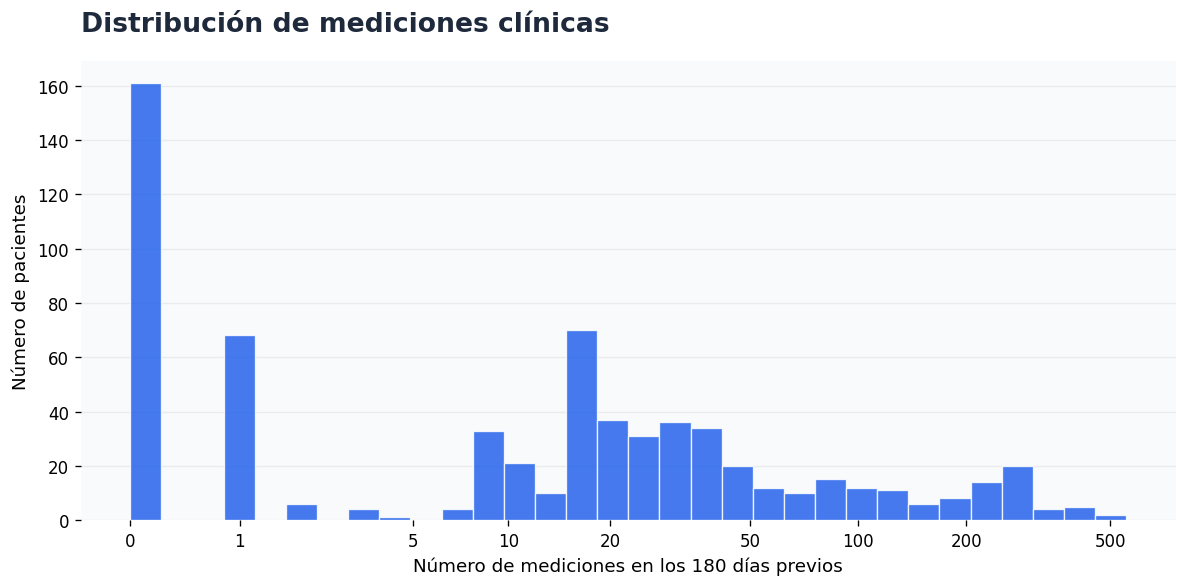

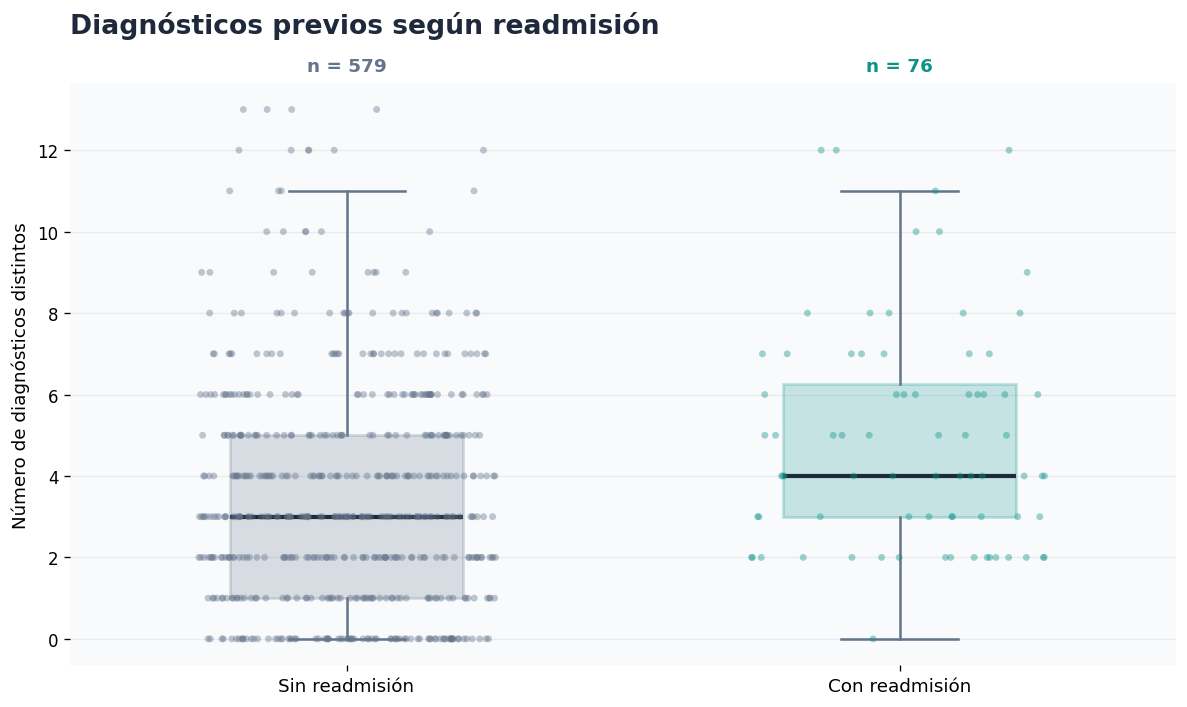

Estadístico U: 16030.50
Valor p: 0.0001058
Delta de Cliff: 0.271


In [7]:
# Paleta de colores
AZUL = "#2563EB"
VERDE = "#0D9488"
GRIS = "#64748B"
TEXTO = "#1E293B"
FONDO = "#F8FAFC"

# GRÁFICA 1. Histograma

datos = df["measurement_count_180d"]

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
fig.patch.set_facecolor("white")
ax.set_facecolor(FONDO)

# Escala logarítmica solo para visualizar
ax.hist(
    np.log1p(datos), bins=32, color=AZUL, edgecolor="white", linewidth=0.8, alpha=0.85
)

# Etiquetas expresadas en número original de mediciones
ticks = [0, 1, 5, 10, 20, 50, 100, 200, 500]
ticks = [t for t in ticks if t <= datos.max()]

ax.set_xticks(np.log1p(ticks))
ax.set_xticklabels(ticks)

ax.set_title(
    "Distribución de mediciones clínicas",
    fontsize=16,
    fontweight="bold",
    color=TEXTO,
    loc="left",
    pad=18,
)

ax.set_xlabel("Número de mediciones en los 180 días previos", fontsize=11)
ax.set_ylabel("Número de pacientes", fontsize=11)

ax.grid(axis="y", alpha=0.20)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

# GRÁFICA 2. Boxplot + TODOS los pacientes

grupos = [
    df.loc[df["readmission_30d"] == 0, "distinct_diagnoses_180d"],
    df.loc[df["readmission_30d"] == 1, "distinct_diagnoses_180d"],
]

colores = [GRIS, VERDE]
etiquetas = ["Sin readmisión", "Con readmisión"]

fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
fig.patch.set_facecolor("white")
ax.set_facecolor(FONDO)

# Boxplots con estilo personalizado
bp = ax.boxplot(
    grupos,
    positions=[1, 2],
    widths=0.42,
    patch_artist=True,
    showfliers=False,  # Evita dibujar dos veces los atípicos
    medianprops=dict(color=TEXTO, linewidth=2.5),
    whiskerprops=dict(color=GRIS, linewidth=1.5),
    capprops=dict(color=GRIS, linewidth=1.5),
)

for caja, color in zip(bp["boxes"], colores):
    caja.set_facecolor(color)
    caja.set_alpha(0.22)
    caja.set_edgecolor(color)
    caja.set_linewidth(1.8)

# Dibujar absolutamente todos los registros
rng = np.random.default_rng(42)

for posicion, (grupo, color) in enumerate(zip(grupos, colores), start=1):
    # Jitter horizontal para reducir superposiciones
    x = rng.uniform(posicion - 0.27, posicion + 0.27, size=len(grupo))

    ax.scatter(x, grupo, s=17, color=color, alpha=0.40, edgecolors="none", zorder=3)

    # Tamaño del grupo
    ax.text(
        posicion,
        1.02,
        f"n = {len(grupo)}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=11,
        fontweight="bold",
        color=color,
    )

ax.set_xticks([1, 2])
ax.set_xticklabels(etiquetas, fontsize=11)

ax.set_title(
    "Diagnósticos previos según readmisión",
    fontsize=16,
    fontweight="bold",
    color=TEXTO,
    loc="left",
    pad=30,
)

ax.set_ylabel("Número de diagnósticos distintos", fontsize=11)
ax.set_xlim(0.5, 2.5)

ax.grid(axis="y", alpha=0.20)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

# Comparación entre ambos grupos
sin_readmision, con_readmision = grupos
u, p = mannwhitneyu(
    sin_readmision, con_readmision, alternative="two-sided", method="asymptotic"
)

# Tamaño del efecto (delta de Cliff)
n0 = len(sin_readmision)
n1 = len(con_readmision)
delta = 1 - (2 * u / (n0 * n1))

print(f"Estadístico U: {u:.2f}")
print(f"Valor p: {p:.4g}")
print(f"Delta de Cliff: {delta:.3f}")

### 7.1. Comparación estadística de diagnósticos previos

En entrenamiento, la prueba U de Mann–Whitney bilateral produjo **U = 16,030.50; p = 0.0001058**. Las medianas fueron 4 en readmitidos y 3 en no readmitidos. El delta de Cliff, orientado a mayores valores en readmitidos, fue **0.271**.

La diferencia es exploratoria y no prueba causalidad ni capacidad predictiva incremental. Las figuras incluyen todos los pacientes de entrenamiento y el jitter se limita a la visualización.



## 8. Preparación de variables para machine learning

El *feature engineering* consiste en transformar datos originales en características que un modelo pueda utilizar para realizar predicciones.

En nuestro proyecto, esta transformación se realizó previamente mediante SQL, utilizando los registros clínicos de los 180 días anteriores al ingreso hospitalario.

Utilizaremos seis variables predictoras:

- **Edad:** años cumplidos al ingreso.
- **Sexo:** categoría femenina o masculina.
- **Hospitalizaciones previas:** número de ingresos hospitalarios en 180 días.
- **Diagnósticos distintos:** número de códigos clínicos diferentes.
- **Medicamentos distintos:** número de códigos de medicamentos diferentes.
- **Mediciones clínicas:** cantidad de registros numéricos de laboratorio y signos vitales.

Nuestra variable objetivo será `readmission_30d`.

No utilizaremos identificadores ni fechas como predictores.

El preprocesamiento posterior, como escalado y codificación de categorías, se realizará dentro de un `Pipeline` de scikit-learn para evitar fugas de información.


In [8]:
# 8. Selección de variables predictoras

variables_numericas = [
    "age",
    "prior_inpatient_hospitalizations_180d",
    "distinct_diagnoses_180d",
    "distinct_medications_180d",
    "measurement_count_180d",
]

variables_categoricas = ["sex"]

variable_objetivo = "readmission_30d"

# X contiene las características de los pacientes
X = df[variables_numericas + variables_categoricas].copy()

# y contiene el desenlace que queremos predecir
y = df[variable_objetivo].astype(int).copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nTipos de variables:")
print(X.dtypes)

print("\nPrimeros cinco pacientes:")
display(X.head())
features = variables_numericas + variables_categoricas
X_train = train_df[features].copy()
y_train = train_df["readmission_30d"].astype(int).copy()
assert X_train.index.equals(y_train.index)
assert len(X_train) == 655 and y_train.sum() == 76

Dimensiones de X: (655, 6)
Dimensiones de y: (655,)

Tipos de variables:
age                                       int64
prior_inpatient_hospitalizations_180d     int64
distinct_diagnoses_180d                   int64
distinct_medications_180d                 int64
measurement_count_180d                    int64
sex                                      object
dtype: object

Primeros cinco pacientes:


,age,prior_inpatient_hospitalizations_180d,distinct_diagnoses_180d,distinct_medications_180d,measurement_count_180d,sex
0,35,0,0,0,0,F
1,41,0,0,1,0,F
2,46,0,3,0,1,M
3,47,0,2,0,1,M
4,45,0,2,0,1,M


## 9. Validación cruzada y desbalance

Se conservan cinco particiones de **StratifiedGroupKFold**, mezcla y semilla 42, agrupadas por `person_id`. Todos los modelos comparten las posiciones de ajuste y validación; cada paciente se valida una vez.

La imputación, escalado y codificación se aprenden dentro de cada fold. AUROC mide ordenamiento; AUPRC es precisión media y se prioriza con desbalance; Brier mide error de probabilidad. Sensibilidad, precisión y especificidad usan 0.50, salvo el análisis exploratorio de umbrales de M0. Se conservan las demás métricas existentes. La desviación entre folds no es un intervalo de confianza.

**Interpretación de las comparaciones.** La tabla final conserva cuatro configuraciones; Dummy es únicamente una referencia sin información clínica. M0 frente a M1 estudia el historial longitudinal; M1 frente a M2 estudia el algoritmo; M2 frente a M2 + FE estudia tres características con idénticos parámetros de XGBoost. Se informan diferencias pareadas por fold, sin tratarlas como cinco muestras independientes ni inferir significancia estadística.

**Reserva temporal.** El tamaño original de la cohorte no implica que 824 pacientes intervengan en los modelos: 655 se utilizan para desarrollo, cuatro se excluyeron por solapamiento y 165 permanecen reservados. La fecha de corte queda fijada a partir de la versión anterior, y la ejecución se detiene si los tamaños esperados cambian.



## 10. Modelo de referencia: DummyClassifier

Antes de desarrollar modelos predictivos, establecemos una referencia utilizando `DummyClassifier`.

Este clasificador no aprende relaciones entre las características clínicas y el desenlace. Con `strategy="prior"`, utiliza la frecuencia de cada clase observada durante el entrenamiento para estimar probabilidades y predice la clase mayoritaria.

Evaluaremos su rendimiento mediante validación cruzada de cinco particiones, agrupando por paciente.

Sus resultados servirán como referencia para comparar la regresión logística y XGBoost.

**El conjunto de prueba temporal permanece reservado para la evaluación final.**


In [9]:
# 10. DUMMYCLASSIFIER — MODELO DE REFERENCIA

# 1. Validación cruzada agrupada por paciente
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Mantendremos los mismos folds para comparar modelos
folds_cv = list(cv.split(X_train, y_train, groups=train_df["person_id"]))

# 2. Métricas
metricas = {
    "Accuracy": "accuracy",
    "Balanced Accuracy": "balanced_accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Sensitivity": make_scorer(recall_score, zero_division=0),
    "Specificity": make_scorer(recall_score, pos_label=0, zero_division=0),
    "F1-score": make_scorer(f1_score, zero_division=0),
    "AUROC": "roc_auc",
    "AUPRC": "average_precision",
    "MCC": "matthews_corrcoef",
    "Brier Score": "neg_brier_score",
}

# 3. Modelo
modelo_dummy = Pipeline([("clasificador", DummyClassifier(strategy="prior"))])

# 4. Validación cruzada
scores_dummy = cross_validate(
    modelo_dummy, X_train, y_train, cv=folds_cv, scoring=metricas
)

# 5. Resultados
resultados_dummy = pd.DataFrame(
    {nombre: scores_dummy[f"test_{nombre}"] for nombre in metricas}
)

resultados_dummy["Brier Score"] *= -1

resumen_dummy = pd.DataFrame(
    {"Media": resultados_dummy.mean(), "Desviación estándar": resultados_dummy.std()}
)

print("DUMMYCLASSIFIER — RESULTADOS POR FOLD")
display(resultados_dummy.round(3))

print("\nRESUMEN")
display(resumen_dummy.round(3))

# Comprobar que se mantienen cinco validaciones independientes por paciente.
assert len(folds_cv) == 5
posiciones_validadas = np.concatenate([validacion for _, validacion in folds_cv])
assert np.array_equal(np.sort(posiciones_validadas), np.arange(len(train_df)))
for ajuste, validacion in folds_cv:
    assert set(train_df.iloc[ajuste]["person_id"]).isdisjoint(
        set(train_df.iloc[validacion]["person_id"])
    )
resumen_folds = pd.DataFrame(
    [
        {
            "Fold": i,
            "Ajuste": len(a),
            "Eventos ajuste": int(y_train.iloc[a].sum()),
            "Validación": len(b),
            "Eventos validación": int(y_train.iloc[b].sum()),
        }
        for i, (a, b) in enumerate(folds_cv, 1)
    ]
).set_index("Fold")
display(resumen_folds)

DUMMYCLASSIFIER — RESULTADOS POR FOLD


,Accuracy,Balanced Accuracy,Precision,Sensitivity,Specificity,F1-score,AUROC,AUPRC,MCC,Brier Score
0,0.885,0.5,0.0,0.0,1.0,0.0,0.5,0.115,0.0,0.101
1,0.878,0.5,0.0,0.0,1.0,0.0,0.5,0.122,0.0,0.107
2,0.885,0.5,0.0,0.0,1.0,0.0,0.5,0.115,0.0,0.101
3,0.885,0.5,0.0,0.0,1.0,0.0,0.5,0.115,0.0,0.101
4,0.885,0.5,0.0,0.0,1.0,0.0,0.5,0.115,0.0,0.101



RESUMEN


,Media,Desviación estándar
Accuracy,0.884,0.003
Balanced Accuracy,0.500,0.000
Precision,0.000,0.000
Sensitivity,0.000,0.000
Specificity,1.000,0.000
F1-score,0.000,0.000
AUROC,0.500,0.000
AUPRC,0.116,0.003
MCC,0.000,0.000
Brier Score,0.103,0.003


,Ajuste,Eventos ajuste,Validación,Eventos validación
Fold,,,,
1,524,61,131,15
2,524,60,131,16
3,524,61,131,15
4,524,61,131,15
5,524,61,131,15



## 11. Modelo M0: regresión logística básica

Construimos una regresión logística regularizada utilizando tres variables:

- Edad al ingreso hospitalario.
- Sexo registrado.
- Hospitalizaciones previas durante los últimos 180 días.

El preprocesamiento se realiza mediante `ColumnTransformer` y `Pipeline`:

1. `SimpleImputer`: trata posibles valores faltantes.
2. `StandardScaler`: estandariza las variables numéricas.
3. `OneHotEncoder`: convierte el sexo en una variable numérica.
4. `LogisticRegression`: aprende a estimar la probabilidad de readmisión.

Evaluamos el modelo mediante las mismas cinco particiones utilizadas para `DummyClassifier`, garantizando una comparación consistente.

**Objetivo:** determinar si estas tres características permiten predecir mejor que un modelo que solamente conoce la prevalencia de readmisión.


In [10]:
def crear_preprocesador(columnas):
    numericas = [c for c in columnas if c != "sex"]
    return ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("imputacion", SimpleImputer(strategy="median")),
                        ("escalado", StandardScaler()),
                    ]
                ),
                numericas,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("imputacion", SimpleImputer(strategy="most_frequent")),
                        (
                            "codificacion",
                            OneHotEncoder(drop="if_binary", handle_unknown="ignore"),
                        ),
                    ]
                ),
                ["sex"],
            ),
        ]
    )


def evaluar_cv(modelo, datos):
    scores = cross_validate(
        modelo,
        datos,
        y_train,
        cv=folds_cv,
        scoring=metricas,
        error_score="raise",
        return_estimator=True,
    )
    # Inspección de los estimadores realmente ajustados en cada fold.
    for estimador, (ajuste, validacion) in zip(scores["estimator"], folds_cv):
        pre = estimador.named_steps["preprocessor"]
        escalador = pre.named_transformers_["num"].named_steps["escalado"]
        assert escalador.n_samples_seen_ == len(ajuste)
        if isinstance(estimador.named_steps["classifier"], XGBClassifier):
            assert (
                estimador.named_steps["classifier"].get_booster().num_boosted_rounds()
                == 100
            )
    resultados = pd.DataFrame({nombre: scores[f"test_{nombre}"] for nombre in metricas})
    resultados["Brier Score"] *= -1
    return scores, resultados


def diferencias_cv(nuevo, referencia):
    return pd.DataFrame(
        {
            f"Delta {m}": nuevo[m] - referencia[m]
            for m in ["AUROC", "AUPRC", "Brier Score"]
        }
    )


variables_m0 = ["age", "sex", "prior_inpatient_hospitalizations_180d"]
modelo_m0 = Pipeline(
    [
        ("preprocessor", crear_preprocesador(variables_m0)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)
scores_m0, resultados_m0 = evaluar_cv(modelo_m0, X_train[variables_m0])
print("M0 — RESULTADOS POR FOLD")
display(resultados_m0.round(3))
comparacion_m0 = pd.DataFrame(
    {
        "Dummy (media)": resultados_dummy.mean(),
        "M0 (media)": resultados_m0.mean(),
        "M0 (DE)": resultados_m0.std(),
    }
)
display(comparacion_m0.round(3))

M0 — RESULTADOS POR FOLD


,Accuracy,Balanced Accuracy,Precision,Sensitivity,Specificity,F1-score,AUROC,AUPRC,MCC,Brier Score
0,0.885,0.5,0.0,0.0,1.0,0.0,0.567,0.147,0.0,0.102
1,0.878,0.5,0.0,0.0,1.0,0.0,0.578,0.205,0.0,0.105
2,0.885,0.5,0.0,0.0,1.0,0.0,0.605,0.149,0.0,0.099
3,0.885,0.5,0.0,0.0,1.0,0.0,0.732,0.231,0.0,0.094
4,0.885,0.5,0.0,0.0,1.0,0.0,0.685,0.252,0.0,0.094


,Dummy (media),M0 (media),M0 (DE)
Accuracy,0.884,0.884,0.003
Balanced Accuracy,0.500,0.500,0.000
Precision,0.000,0.000,0.000
Sensitivity,0.000,0.000,0.000
Specificity,1.000,1.000,0.000
F1-score,0.000,0.000,0.000
AUROC,0.500,0.633,0.072
AUPRC,0.116,0.197,0.047
MCC,0.000,0.000,0.000
Brier Score,0.103,0.099,0.005



## 11.2. Ajuste del umbral de clasificación

Debido al desbalance entre pacientes readmitidos y no readmitidos, el umbral convencional de 0.50 puede producir una sensibilidad muy baja.

Evaluamos diferentes umbrales de probabilidad para estudiar el equilibrio entre:

- **Sensibilidad:** proporción de readmisiones identificadas correctamente.
- **Precisión:** proporción de alertas positivas que corresponden a readmisiones reales.
- **Especificidad:** proporción de pacientes no readmitidos identificados correctamente.
- **F2-score:** medida que otorga mayor importancia a la sensibilidad que a la precisión.

Las probabilidades se obtienen mediante predicciones fuera de muestra (*out-of-fold*) en el conjunto de entrenamiento.

Reducir el umbral puede aumentar la sensibilidad, pero también producir más falsos positivos.

Este análisis es exploratorio. El umbral definitivo deberá seleccionarse sin consultar el conjunto de prueba temporal.


COMPARACIÓN DE UMBRALES — M0


,Umbral,Sensibilidad,Precisión,Especificidad,F2-score,VP,FP,FN,VN
0,0.050,1.000,0.117,0.014,0.400,76,571,0,8
1,0.075,0.750,0.176,0.539,0.454,57,267,19,312
2,0.100,0.750,0.176,0.541,0.455,57,266,19,313
3,0.125,0.750,0.176,0.541,0.455,57,266,19,313
4,0.150,0.750,0.177,0.542,0.455,57,265,19,314
5,0.200,0.039,0.500,0.995,0.048,3,3,73,576
6,0.300,0.039,0.500,0.995,0.048,3,3,73,576
7,0.500,0.000,0.000,1.000,0.000,0,0,76,579


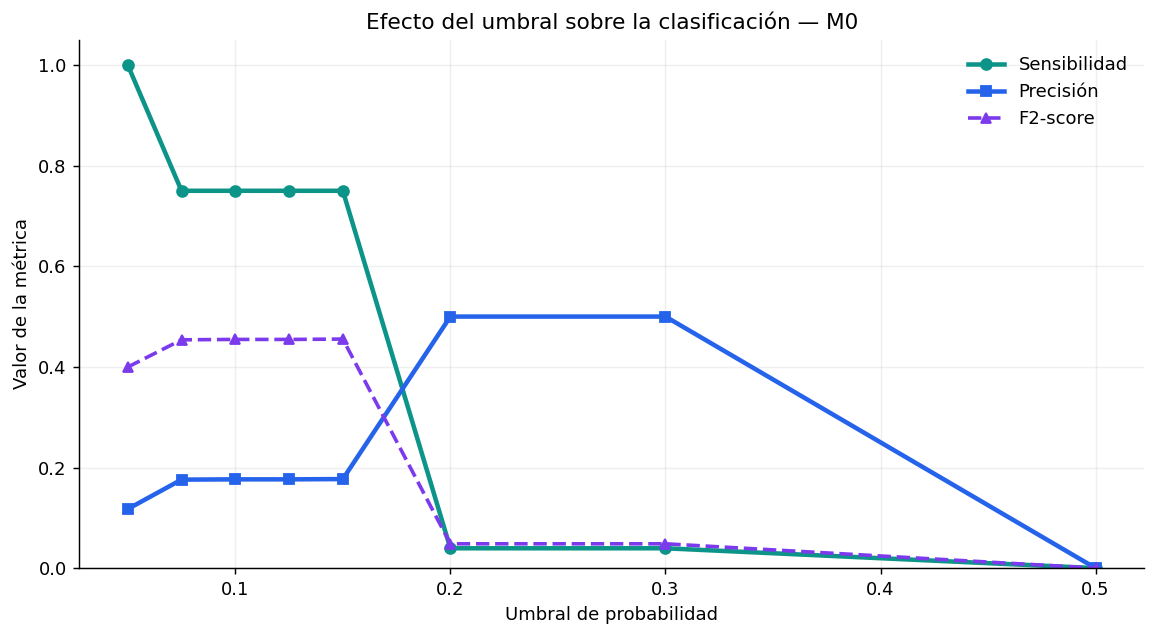

In [11]:
# 11.2. AJUSTE DEL UMBRAL DE CLASIFICACIÓN — M0

# 1. Obtener probabilidades fuera de muestra mediante CV
probabilidades_m0 = cross_val_predict(
    modelo_m0, X_train[variables_m0], y_train, cv=folds_cv, method="predict_proba"
)[:, 1]

# 2. Probar distintos umbrales
umbrales = [0.05, 0.075, 0.10, 0.125, 0.15, 0.20, 0.30, 0.50]

resultados = []

for umbral in umbrales:
    # Convertir probabilidades en clases
    pred = (probabilidades_m0 >= umbral).astype(int)

    # Matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_train, pred, labels=[0, 1]).ravel()

    resultados.append(
        {
            "Umbral": umbral,
            "Sensibilidad": recall_score(y_train, pred),
            "Precisión": precision_score(y_train, pred, zero_division=0),
            "Especificidad": tn / (tn + fp),
            "F2-score": fbeta_score(y_train, pred, beta=2, zero_division=0),
            "VP": tp,
            "FP": fp,
            "FN": fn,
            "VN": tn,
        }
    )

tabla_umbrales = pd.DataFrame(resultados)

print("COMPARACIÓN DE UMBRALES — M0")
display(tabla_umbrales.round(3))

# 3. Visualizar el compromiso entre sensibilidad y precisión
fig, ax = plt.subplots(figsize=(9, 5), dpi=130)

ax.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["Sensibilidad"],
    marker="o",
    linewidth=2.5,
    label="Sensibilidad",
    color="#0D9488",
)

ax.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["Precisión"],
    marker="s",
    linewidth=2.5,
    label="Precisión",
    color="#2563EB",
)

ax.plot(
    tabla_umbrales["Umbral"],
    tabla_umbrales["F2-score"],
    marker="^",
    linewidth=2,
    linestyle="--",
    label="F2-score",
    color="#7C3AED",
)

ax.set(
    title="Efecto del umbral sobre la clasificación — M0",
    xlabel="Umbral de probabilidad",
    ylabel="Valor de la métrica",
    ylim=(0, 1.05),
)

ax.grid(alpha=0.2)
ax.legend(frameon=False)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


### 11.2.1. Interpretación del ajuste de umbral

El umbral convencional de 0.50 produjo una sensibilidad de cero, por lo que el modelo M0 no identificó ninguna readmisión.

Al reducir el umbral a 0.15, la sensibilidad aumentó al **75%**, identificando 57 de las 76 readmisiones presentes en entrenamiento.

Sin embargo, la precisión fue de **17.7%**, con 265 falsos positivos y 19 falsos negativos.

El F2-score alcanzó aproximadamente 0.455.

**Conclusión:** reducir el umbral permite detectar más readmisiones, pero aumenta considerablemente el número de falsas alarmas.

El cambio de umbral no modifica las probabilidades estimadas ni mejora el AUROC o AUPRC del modelo.

Los resultados son exploratorios y proceden de predicciones fuera de muestra obtenidas mediante validación cruzada. La selección del umbral sobre estas mismas predicciones puede generar estimaciones optimistas; su rendimiento deberá evaluarse posteriormente sobre datos independientes.


## 12. Modelo M1: regresión logística con historial clínico

Añade los tres conteos longitudinales a M0, con seis predictores. Se conservan el clasificador, los parámetros y los folds. El preprocesamiento se aprende dentro de cada fold.


In [12]:
variables_m1 = variables_numericas + variables_categoricas
modelo_m1 = Pipeline(
    [
        ("preprocessor", crear_preprocesador(variables_m1)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)
scores_m1, resultados_m1 = evaluar_cv(modelo_m1, X_train[variables_m1])
print("M1 — RESULTADOS POR FOLD")
display(resultados_m1.round(3))
comparacion_modelos = pd.DataFrame(
    {
        "Dummy": resultados_dummy.mean(),
        "M0": resultados_m0.mean(),
        "M1": resultados_m1.mean(),
    }
)
display(comparacion_modelos.round(3))
print("DIFERENCIAS M1 - M0")
display(diferencias_cv(resultados_m1, resultados_m0).mean().round(3))

M1 — RESULTADOS POR FOLD


,Accuracy,Balanced Accuracy,Precision,Sensitivity,Specificity,F1-score,AUROC,AUPRC,MCC,Brier Score
0,0.885,0.500,0.0,0.000,1.0,0.000,0.553,0.137,0.000,0.106
1,0.878,0.500,0.0,0.000,1.0,0.000,0.639,0.319,0.000,0.104
2,0.885,0.500,0.0,0.000,1.0,0.000,0.714,0.204,0.000,0.098
3,0.885,0.500,0.0,0.000,1.0,0.000,0.783,0.308,0.000,0.091
4,0.893,0.533,1.0,0.067,1.0,0.125,0.764,0.337,0.244,0.092


,Dummy,M0,M1
Accuracy,0.884,0.884,0.885
Balanced Accuracy,0.500,0.500,0.507
Precision,0.000,0.000,0.200
Sensitivity,0.000,0.000,0.013
Specificity,1.000,1.000,1.000
F1-score,0.000,0.000,0.025
AUROC,0.500,0.633,0.691
AUPRC,0.116,0.197,0.261
MCC,0.000,0.000,0.049
Brier Score,0.103,0.099,0.098


DIFERENCIAS M1 - M0


Delta AUROC          0.057
Delta AUPRC          0.064
Delta Brier Score   -0.001
dtype: float64

### 12.1. Comparación entre M0 y M1

La incorporación del historial clínico mejoró el rendimiento predictivo promedio durante la validación cruzada.

M1 obtuvo un **AUROC de 0.691**, frente a 0.633 de M0, y un **AUPRC de 0.261**, frente a 0.197.

El Brier Score disminuyó ligeramente de 0.099 a 0.098.

Sin embargo, con el umbral convencional de 0.50, M1 presentó una sensibilidad media de apenas 0.013, identificando muy pocas readmisiones.

**Interpretación:** los diagnósticos, medicamentos y mediciones previas parecen aportar información predictiva adicional, aunque todavía no se ha demostrado una mejora estadísticamente concluyente ni utilidad clínica.

El análisis previo de umbrales corresponde a M0 y es exploratorio; no modifica esta comparación ni selecciona un umbral definitivo para prueba.



## 13. Ingeniería de variables: frecuencia de diagnósticos y medicamentos

Exploramos los códigos de condiciones clínicas y medicamentos registrados durante los 180 días anteriores a la hospitalización índice.

El objetivo es identificar:

1. Los diagnósticos y medicamentos más frecuentes entre los pacientes.
2. Cuántas veces aparece cada código en un mismo paciente.
3. Cuántos pacientes presentan registros repetidos del mismo código.
4. Posibles nuevas variables predictoras relacionadas con la frecuencia de registros clínicos.

Distinguimos entre **frecuencia de pacientes** (cuántas personas presentan un código) y **frecuencia de registros** (cuántas veces aparece ese código).

Utilizamos exclusivamente los pacientes de entrenamiento. Las variables no se incorporarán automáticamente a los modelos: primero evaluaremos su interpretación clínica y su pertinencia.

**Limitación:** un diagnóstico registrado repetidamente no necesariamente representa episodios independientes de enfermedad. Del mismo modo, múltiples registros de un medicamento no equivalen necesariamente a dosis consumidas.


In [13]:
# 13. FEATURE ENGINEERING:
# FRECUENCIA DE DIAGNÓSTICOS Y MEDICAMENTOS

# 13.1. LOCALIZAR LAS BASES DE DATOS

rutas_raw = [raiz / "lab10/data/clinical.duckdb"]

ruta_raw = next((ruta.resolve() for ruta in rutas_raw if ruta.is_file()), None)

if ruta_raw is None:
    raise FileNotFoundError("No se encontró clinical.duckdb")

ruta_omop = Path(db_path).resolve()

if not ruta_omop.is_file():
    raise FileNotFoundError("No se encontró omop_minimal.duckdb")

# 13.2. RECUPERAR DIAGNÓSTICOS Y MEDICAMENTOS

# Base temporal en memoria: no modifica los archivos originales
con = duckdb.connect(":memory:")

try:
    con.execute(
        f"ATTACH '{str(ruta_omop).replace(chr(39), chr(39) * 2)}' "
        "AS db_omop (READ_ONLY)"
    )

    con.execute(
        f"ATTACH '{str(ruta_raw).replace(chr(39), chr(39) * 2)}' AS db_raw (READ_ONLY)"
    )

    # Pacientes exclusivos del entrenamiento
    con.register("cohorte_train", train_df[["person_id", "index_admission"]])

    consulta = """
    WITH base AS (
        SELECT
            t.person_id,
            t.index_admission,
            p.person_source_value
        FROM cohorte_train t
        JOIN db_omop.omop.person p
          ON t.person_id = p.person_id
    ),

    eventos AS (

        -- Diagnósticos de los 180 días anteriores
        SELECT
            'Diagnóstico' AS tipo,
            b.person_id,
            c.condition_source_value AS codigo,
            c.condition_source_description AS descripcion
        FROM base b
        JOIN db_omop.omop.condition_occurrence c
          ON c.person_id = b.person_id
         AND c.condition_start_date >=
             CAST(
                 b.index_admission - INTERVAL 180 DAY
                 AS DATE
             )
         AND c.condition_start_date <
             CAST(b.index_admission AS DATE)
        WHERE c.condition_source_value IS NOT NULL

        UNION ALL

        -- Medicamentos de los 180 días anteriores
        SELECT
            'Medicamento' AS tipo,
            b.person_id,
            m.code AS codigo,
            m.description AS descripcion
        FROM base b
        JOIN db_raw.main.medications m
          ON CAST(m.patient_id AS VARCHAR) = b.person_source_value
         AND m.start_at >=
             b.index_admission - INTERVAL 180 DAY
         AND m.start_at < b.index_admission
        WHERE m.code IS NOT NULL
    )

    SELECT
        tipo,
        person_id,
        codigo,
        MAX(descripcion) AS descripcion,
        COUNT(*) AS apariciones
    FROM eventos
    GROUP BY tipo, person_id, codigo
    ORDER BY tipo, person_id, apariciones DESC
    """

    registros = con.execute(consulta).df()

finally:
    con.close()

print("CÓDIGOS POR PACIENTE")
display(registros.head(15))

# 13.3. RANKING GENERAL DE CÓDIGOS

ranking = registros.groupby(["tipo", "codigo"], as_index=False).agg(
    descripcion=("descripcion", "first"),
    pacientes=("person_id", "nunique"),
    registros_totales=("apariciones", "sum"),
    pacientes_con_repeticiones=("apariciones", lambda x: (x >= 2).sum()),
)

# Porcentaje respecto al total de pacientes de entrenamiento
ranking["porcentaje_pacientes"] = (ranking["pacientes"] / len(train_df) * 100).round(2)

# 13.4. TOP 15 DE DIAGNÓSTICOS Y MEDICAMENTOS

for tipo in ["Diagnóstico", "Medicamento"]:
    top = (
        ranking[ranking["tipo"] == tipo]
        .sort_values(["pacientes", "registros_totales"], ascending=False)
        .head(15)
    )

    print(f"\nTOP 15 — {tipo.upper()}")

    display(
        top[
            [
                "codigo",
                "descripcion",
                "pacientes",
                "porcentaje_pacientes",
                "registros_totales",
                "pacientes_con_repeticiones",
            ]
        ].reset_index(drop=True)
    )

# 13.5. CÓDIGOS MÁS REPETIDOS EN UN MISMO PACIENTE

print("\nTOP 15 — MAYORES REPETICIONES POR PACIENTE")

top_repeticiones = registros.sort_values("apariciones", ascending=False).head(15)

display(top_repeticiones.reset_index(drop=True))

# 13.6. RESUMEN

print("\nRESUMEN GENERAL")

print("Pacientes de entrenamiento:", len(train_df))

print(
    "Pacientes con diagnósticos registrados:",
    registros.loc[registros["tipo"] == "Diagnóstico", "person_id"].nunique(),
)

print(
    "Pacientes con medicamentos registrados:",
    registros.loc[registros["tipo"] == "Medicamento", "person_id"].nunique(),
)

print("Códigos diferentes encontrados:", ranking.shape[0])

CÓDIGOS POR PACIENTE


,tipo,person_id,codigo,descripcion,apariciones
0,Diagnóstico,25,741062008,Not in labor force (finding),1
1,Diagnóstico,25,274531002,Abnormal findings diagnostic imaging heart+cor...,1
2,Diagnóstico,25,66383009,Gingivitis (disorder),1
3,Diagnóstico,25,414545008,Ischemic heart disease (disorder),1
4,Diagnóstico,35,713197008,Recurrent rectal polyp (disorder),1
5,Diagnóstico,35,109838007,Overlapping malignant neoplasm of colon (disor...,1
6,Diagnóstico,76,713197008,Recurrent rectal polyp (disorder),1
7,Diagnóstico,76,363406005,Malignant neoplasm of colon (disorder),1
8,Diagnóstico,76,427898007,Infection of tooth (disorder),1
9,Diagnóstico,81,423315002,Limited social contact (finding),1



TOP 15 — DIAGNÓSTICO


,codigo,descripcion,pacientes,porcentaje_pacientes,registros_totales,pacientes_con_repeticiones
0,314529007,Medication review due (situation),223,34.05,388,76
1,162573006,Suspected lung cancer (situation),192,29.31,192,0
2,254637007,Non-small cell lung cancer (disorder),165,25.19,165,0
3,73595000,Stress (finding),145,22.14,169,20
4,713197008,Recurrent rectal polyp (disorder),138,21.07,138,0
5,66383009,Gingivitis (disorder),137,20.92,160,19
6,160903007,Full-time employment (finding),130,19.85,152,16
7,160904001,Part-time employment (finding),90,13.74,99,7
8,363406005,Malignant neoplasm of colon (disorder),88,13.44,88,0
9,109838007,Overlapping malignant neoplasm of colon (disor...,84,12.82,84,0



TOP 15 — MEDICAMENTO


,codigo,descripcion,pacientes,porcentaje_pacientes,registros_totales,pacientes_con_repeticiones
0,1535362,sodium fluoride 0.0272 MG/MG Oral Gel,129,19.69,153,19
1,310798,Hydrochlorothiazide 25 MG Oral Tablet,120,18.32,382,62
2,314076,lisinopril 10 MG Oral Tablet,115,17.56,367,66
3,106892,insulin isophane human 70 UNT/ML / insulin r...,92,14.05,428,78
4,308136,amLODIPine 2.5 MG Oral Tablet,87,13.28,238,43
5,314231,Simvastatin 10 MG Oral Tablet,48,7.33,48,0
6,313521,tropicamide 5 MG/ML Ophthalmic Solution,35,5.34,38,2
7,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],26,3.97,908,26
8,705129,Nitroglycerin 0.4 MG/ACTUAT Mucosal Spray,26,3.97,26,0
9,866412,24 HR metoprolol succinate 100 MG Extended Rel...,26,3.97,26,0



TOP 15 — MAYORES REPETICIONES POR PACIENTE


,tipo,person_id,codigo,descripcion,apariciones
0,Medicamento,5834,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],54
1,Medicamento,16774,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],54
2,Medicamento,18738,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],52
3,Medicamento,8083,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],51
4,Medicamento,19364,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],50
5,Medicamento,17895,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],50
6,Medicamento,9340,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],48
7,Medicamento,21543,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],48
8,Medicamento,18326,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],46
9,Medicamento,11341,205923,1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],43



RESUMEN GENERAL
Pacientes de entrenamiento: 655
Pacientes con diagnósticos registrados: 572
Pacientes con medicamentos registrados: 374
Códigos diferentes encontrados: 235


In [14]:
# 13.8. ENFERMEDADES NO ONCOLÓGICAS

# Trabajar con los registros ya recuperados del entrenamiento
diagnosticos = registros[registros["tipo"] == "Diagnóstico"].copy()

diagnosticos["descripcion"] = diagnosticos["descripcion"].fillna("").astype(str)

# Excluir códigos relacionados con cáncer y neoplasias
patron_cancer = (
    r"cancer|carcinom|malignan|neoplasm|leukem|"
    r"lymphom|melanom|metasta|sarcom|myelom|tumou?r"
)

diagnosticos = diagnosticos[
    ~diagnosticos["descripcion"].str.contains(patron_cancer, case=False, regex=True)
].copy()

# Conservar las condiciones etiquetadas como trastornos.
# Excluye muchas situaciones administrativas y hallazgos.
diagnosticos = diagnosticos[
    diagnosticos["descripcion"].str.contains(r"\(disorder\)", case=False, regex=True)
].copy()

# Ranking de enfermedades distintas, no oncológicas
ranking_enfermedades = (
    diagnosticos.groupby(["codigo", "descripcion"], as_index=False)
    .agg(pacientes=("person_id", "nunique"), registros=("apariciones", "sum"))
    .sort_values(["pacientes", "registros"], ascending=False)
)

print("TOP 25 — ENFERMEDADES NO ONCOLÓGICAS")
display(ranking_enfermedades.head(25))

# 13.9. AGRUPACIÓN CLÍNICA DE VARIABLES

# Grupos de comorbilidades no oncológicas
grupos_diagnosticos = {
    "dx_diabetes": r"\bdiabetes\b|\bdiabetic\b",
    "dx_hipertension": r"hypertension|hypertensive",
    "dx_cardiovascular": (
        r"heart failure|cardiac failure|coronary|"
        r"ischemic heart|ischaemic heart|"
        r"myocardial infarction|atrial fibrillation|"
        r"cardiomyopath"
    ),
    "dx_renal": (
        r"chronic kidney|kidney failure|renal failure|"
        r"renal insufficien|nephropathy|acute kidney"
    ),
    "dx_pulmonar": (
        r"chronic obstructive|copd|asthma|"
        r"emphysema|chronic bronchitis"
    ),
    "dx_anemia": r"anemia|anaemia",
    "dx_obesidad": r"obes",
    "dx_depresion": r"depressi(on|ve)",
    "dx_hepatica": (
        r"cirrhosis|hepatitis|hepatic failure|"
        r"liver failure|fatty liver"
    ),
}

# Familias farmacológicas aproximadas
grupos_medicamentos = {
    "med_antihipertensivos": (
        r"hydrochlorothiazide|lisinopril|amlodipine|"
        r"losartan|valsartan|enalapril|metoprolol|"
        r"atenolol|carvedilol|nifedipine"
    ),
    "med_antidiabeticos": (
        r"\binsulin\b|metformin|glipizide|glyburide|"
        r"glimepiride|sitagliptin|semaglutide|"
        r"empagliflozin|liraglutide"
    ),
    "med_estatinas": (
        r"atorvastatin|simvastatin|rosuvastatin|"
        r"pravastatin|lovastatin"
    ),
    "med_antitromboticos": (
        r"clopidogrel|warfarin|apixaban|rivaroxaban|"
        r"enoxaparin|heparin|dabigatran"
    ),
    "med_antineoplasicos": (
        r"paclitaxel|docetaxel|cisplatin|carboplatin|"
        r"doxorubicin|cyclophosphamide|oxaliplatin|"
        r"fluorouracil|capecitabine|gemcitabine"
    ),
    "med_eritropoyetina": r"epoetin|darbepoetin",
    "med_analgesicos": (
        r"acetaminophen|paracetamol|ibuprofen|"
        r"naproxen|morphine|oxycodone|fentanyl|tramadol"
    ),
    "med_antibioticos": (
        r"amoxicillin|azithromycin|doxycycline|"
        r"cephalexin|ciprofloxacin|ceftriaxone|"
        r"clindamycin|vancomycin"
    ),
}

# Crear una fila por paciente de entrenamiento
features_clinicas = train_df[["person_id", "readmission_30d"]].copy()

medicamentos = registros[registros["tipo"] == "Medicamento"].copy()

medicamentos["descripcion"] = medicamentos["descripcion"].fillna("").astype(str)


# Función para registrar presencia (1) o ausencia de registro (0)
def agregar_grupos(tabla_registros, patrones):
    for nombre, patron in patrones.items():
        pacientes = tabla_registros.loc[
            tabla_registros["descripcion"].str.contains(patron, case=False, regex=True),
            "person_id",
        ].unique()

        features_clinicas[nombre] = (
            features_clinicas["person_id"].isin(pacientes).astype(int)
        )


# Aplicar las mismas reglas a todos los pacientes
agregar_grupos(diagnosticos, grupos_diagnosticos)
agregar_grupos(medicamentos, grupos_medicamentos)

print("VARIABLES CLÍNICAS POR PACIENTE")
display(features_clinicas.head(10))

TOP 25 — ENFERMEDADES NO ONCOLÓGICAS


,codigo,descripcion,pacientes,registros
63,713197008,Recurrent rectal polyp (disorder),138,138
60,66383009,Gingivitis (disorder),137,160
19,271737000,Anemia (disorder),42,42
9,18718003,Gingival disease (disorder),41,45
61,68496003,Polyp of colon (disorder),37,37
47,444814009,Viral sinusitis (disorder),34,35
1,109570002,Primary dental caries (disorder),32,33
37,414545008,Ischemic heart disease (disorder),28,28
54,6072007,Bleeding from anus (disorder),26,26
11,195662009,Acute viral pharyngitis (disorder),23,23


VARIABLES CLÍNICAS POR PACIENTE


/tmp/ipykernel_3195413/1438435794.py:149: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  tabla_registros["descripcion"].str.contains(


,person_id,readmission_30d,dx_diabetes,dx_hipertension,dx_cardiovascular,dx_renal,dx_pulmonar,dx_anemia,dx_obesidad,dx_depresion,dx_hepatica,med_antihipertensivos,med_antidiabeticos,med_estatinas,med_antitromboticos,med_antineoplasicos,med_eritropoyetina,med_analgesicos,med_antibioticos
0,22342,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,19061,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
2,3308,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,12566,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,4337,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,15119,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,8196,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0
7,8587,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,2027,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
9,18045,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0


In [15]:
# 13.10. ASOCIACIÓN EXPLORATORIA CON READMISIÓN


def comparar_readmisiones(columnas):
    resultados = []
    total_eventos = features_clinicas["readmission_30d"].sum()

    for columna in columnas:
        presente = features_clinicas[columna] == 1

        n_si = int(presente.sum())
        n_no = int((~presente).sum())

        eventos_si = int(features_clinicas.loc[presente, "readmission_30d"].sum())

        eventos_no = int(total_eventos - eventos_si)

        tasa_si = 100 * eventos_si / n_si if n_si > 0 else float("nan")

        tasa_no = 100 * eventos_no / n_no if n_no > 0 else float("nan")

        resultados.append(
            {
                "Grupo": columna,
                "Pacientes": n_si,
                "Readmisiones": eventos_si,
                "Readmisión con grupo (%)": tasa_si,
                "Readmisión sin grupo (%)": tasa_no,
                "Diferencia (pp)": tasa_si - tasa_no,
            }
        )

    return (
        pd.DataFrame(resultados)
        .sort_values("Pacientes", ascending=False)
        .reset_index(drop=True)
    )


# Diagnósticos no oncológicos
tabla_dx = comparar_readmisiones(list(grupos_diagnosticos))

print("COMORBILIDADES Y READMISIÓN")
display(tabla_dx.round(2))

# Familias de medicamentos
tabla_med = comparar_readmisiones(list(grupos_medicamentos))

print("\nMEDICAMENTOS Y READMISIÓN")
display(tabla_med.round(2))

print("\nREADMISIÓN GENERAL EN ENTRENAMIENTO:")
print(f"{100 * train_df['readmission_30d'].mean():.2f}%")

# 13.11. ANÁLISIS ESTADÍSTICO DE CANDIDATAS

grupos = list(grupos_diagnosticos.keys()) + list(grupos_medicamentos.keys())

resultados_estadisticos = []

for variable in grupos:
    presente = features_clinicas[variable] == 1
    readmitido = features_clinicas["readmission_30d"] == 1

    vp = int((presente & readmitido).sum())
    fp = int((presente & ~readmitido).sum())
    fn = int((~presente & readmitido).sum())
    vn = int((~presente & ~readmitido).sum())

    tabla = [[vp, fp], [fn, vn]]

    odds_ratio, p_valor = fisher_exact(tabla)

    resultados_estadisticos.append(
        {
            "Variable": variable,
            "Pacientes": vp + fp,
            "Readmisiones": vp,
            "Odds ratio": odds_ratio,
            "p_Fisher": p_valor,
        }
    )

tabla_estadistica = pd.DataFrame(resultados_estadisticos)

tabla_estadistica["FDR_BH"] = multipletests(
    tabla_estadistica["p_Fisher"], method="fdr_bh"
)[1]

tabla_estadistica = tabla_estadistica.sort_values("p_Fisher")

print("ANÁLISIS ESTADÍSTICO DE LAS 17 VARIABLES")
display(tabla_estadistica.round(4))

# Correlación phi entre las dos variables binarias
correlacion = (
    features_clinicas[["dx_cardiovascular", "med_antihipertensivos"]].corr().iloc[0, 1]
)

print("\nCORRELACIÓN PHI ENTRE LAS DOS CANDIDATAS")
print(f"Phi = {correlacion:.3f}")

print("\nTABLA DE COOCURRENCIA")
display(
    pd.crosstab(
        features_clinicas["dx_cardiovascular"],
        features_clinicas["med_antihipertensivos"],
    )
)

COMORBILIDADES Y READMISIÓN


,Grupo,Pacientes,Readmisiones,Readmisión con grupo (%),Readmisión sin grupo (%),Diferencia (pp)
0,dx_anemia,42,1,2.38,12.23,-9.85
1,dx_cardiovascular,37,9,24.32,10.84,13.48
2,dx_diabetes,9,2,22.22,11.46,10.77
3,dx_renal,8,3,37.50,11.28,26.22
4,dx_hipertension,5,1,20.00,11.54,8.46
5,dx_pulmonar,0,0,NaN,11.60,NaN
6,dx_obesidad,0,0,NaN,11.60,NaN
7,dx_depresion,0,0,NaN,11.60,NaN
8,dx_hepatica,0,0,NaN,11.60,NaN



MEDICAMENTOS Y READMISIÓN


,Grupo,Pacientes,Readmisiones,Readmisión con grupo (%),Readmisión sin grupo (%),Diferencia (pp)
0,med_antihipertensivos,197,32,16.24,9.61,6.64
1,med_antidiabeticos,107,18,16.82,10.58,6.24
2,med_analgesicos,89,5,5.62,12.54,-6.93
3,med_estatinas,70,11,15.71,11.11,4.60
4,med_antineoplasicos,36,1,2.78,12.12,-9.34
5,med_antitromboticos,27,5,18.52,11.31,7.21
6,med_eritropoyetina,26,2,7.69,11.76,-4.07
7,med_antibioticos,9,2,22.22,11.46,10.77



READMISIÓN GENERAL EN ENTRENAMIENTO:
11.60%
ANÁLISIS ESTADÍSTICO DE LAS 17 VARIABLES


,Variable,Pacientes,Readmisiones,Odds ratio,p_Fisher,FDR_BH
9,med_antihipertensivos,197,32,1.8248,0.0170,0.2142
2,dx_cardiovascular,37,9,2.6434,0.0287,0.2142
3,dx_renal,8,3,4.7178,0.0547,0.2142
10,med_antidiabeticos,107,18,1.7086,0.0706,0.2142
15,med_analgesicos,89,5,0.4150,0.0730,0.2142
5,dx_anemia,42,1,0.1750,0.0756,0.2142
13,med_antineoplasicos,36,1,0.2072,0.1082,0.2628
12,med_antitromboticos,27,5,1.7830,0.2272,0.4341
11,med_estatinas,70,11,1.4915,0.2407,0.4341
0,dx_diabetes,9,2,2.2085,0.2809,0.4341



CORRELACIÓN PHI ENTRE LAS DOS CANDIDATAS
Phi = 0.287

TABLA DE COOCURRENCIA


med_antihipertensivos,0,1
dx_cardiovascular,,
0,452,166
1,6,31


### 13.11.1. Interpretación del análisis estadístico de variables clínicas

Se analizaron 17 características clínicas mediante la prueba exacta de Fisher para explorar su asociación con la readmisión hospitalaria a 30 días. Se aplicó la corrección de Benjamini-Hochberg (FDR) para controlar las comparaciones múltiples.

**Principales resultados:**

| Variable | Pacientes | Odds ratio | Valor p | FDR |
|---|---:|---:|---:|---:|
| Antihipertensivos | 197 | 1.82 | 0.0170 | 0.2142 |
| Enfermedad cardiovascular | 37 | 2.64 | 0.0287 | 0.2142 |
| Enfermedad renal | 8 | 4.72 | 0.0547 | 0.2142 |
| Antidiabéticos | 107 | 1.71 | 0.0706 | 0.2142 |

Los antihipertensivos y las enfermedades cardiovasculares presentaron asociaciones nominales con la readmisión (p < 0.05). Sin embargo, **ninguna característica mantuvo significancia estadística después de corregir por comparaciones múltiples (FDR < 0.05)**.

La enfermedad renal mostró una asociación aparentemente elevada, pero solamente ocho pacientes presentaron esta condición, lo que limita la estabilidad de la estimación.

**Análisis de correlación**

La correlación phi entre enfermedad cardiovascular y uso de antihipertensivos fue de **0.287**, indicando una asociación positiva de magnitud baja a moderada.

De los 37 pacientes con enfermedad cardiovascular registrada, 31 también presentaron registros de antihipertensivos. Aunque existe solapamiento, ambas características representan información clínica diferente.


**Decisión para la versión 2.3**

`dx_cardiovascular` y `med_antihipertensivos` se incorporan únicamente a M2 + FE, junto con el conteo no oncológico. M2 utiliza exactamente los seis predictores de M1.

**Limitación:** las características surgieron de explorar el entrenamiento completo. Compararlas con los mismos folds puede ser optimista por selección. Las asociaciones no son causales ni constituyen validación independiente. La prueba permanece reservada.


## 14. Modelo M2: XGBoost con historial clínico

**Objetivo:** aislar el efecto del algoritmo comparando M1 y M2 con exactamente los mismos seis predictores, pacientes, folds y preprocesamiento.

**Metodología:** XGBoost binario en CPU, 100 árboles, profundidad 2, tasa de aprendizaje 0.03, `min_child_weight=5`, `gamma=0.1`, L1=0.1, L2=5, submuestreo=0.8, columnas=1.0 y semilla 42. Sin ponderación de clases, parada temprana ni búsqueda de hiperparámetros. La configuración se fija antes de ejecutar esta versión y se reutiliza sin cambios en M2 + FE.

Se mantiene el escalado para usar el mismo preprocesamiento, aunque los árboles no lo requieren. Las tablas siguientes corresponden al nuevo XGBoost; no a la regresión logística anterior.


In [16]:
variables_m2 = variables_m1.copy()
X_train_m2 = X_train[variables_m2].copy()
assert variables_m2 == variables_m1 and X_train_m2.shape == (655, 6)

parametros_xgb = dict(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=5,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=5.0,
    subsample=0.8,
    colsample_bytree=1.0,
    scale_pos_weight=1.0,
    tree_method="hist",
    device="cpu",
    n_jobs=1,
    random_state=42,
)
modelo_m2 = Pipeline(
    [
        ("preprocessor", crear_preprocesador(variables_m2)),
        ("classifier", XGBClassifier(**parametros_xgb)),
    ]
)
scores_m2, resultados_m2 = evaluar_cv(modelo_m2, X_train_m2)
print("M2 — XGBOOST CON SEIS VARIABLES")
display(resultados_m2.round(3))
comparacion_m2 = pd.DataFrame(
    {"M0": resultados_m0.mean(), "M1": resultados_m1.mean(), "M2": resultados_m2.mean()}
)
display(comparacion_m2.round(3))
diferencias = diferencias_cv(resultados_m2, resultados_m1)
print("DIFERENCIAS M2 - M1: EFECTO DEL ALGORITMO")
display(diferencias.round(3))
display(diferencias.mean().round(3))

M2 — XGBOOST CON SEIS VARIABLES


,Accuracy,Balanced Accuracy,Precision,Sensitivity,Specificity,F1-score,AUROC,AUPRC,MCC,Brier Score
0,0.885,0.5,0.0,0.0,1.0,0.0,0.568,0.203,0.0,0.103
1,0.878,0.5,0.0,0.0,1.0,0.0,0.629,0.169,0.0,0.105
2,0.885,0.5,0.0,0.0,1.0,0.0,0.677,0.172,0.0,0.098
3,0.885,0.5,0.0,0.0,1.0,0.0,0.752,0.245,0.0,0.095
4,0.885,0.5,0.0,0.0,1.0,0.0,0.769,0.320,0.0,0.094


,M0,M1,M2
Accuracy,0.884,0.885,0.884
Balanced Accuracy,0.500,0.507,0.500
Precision,0.000,0.200,0.000
Sensitivity,0.000,0.013,0.000
Specificity,1.000,1.000,1.000
F1-score,0.000,0.025,0.000
AUROC,0.633,0.691,0.679
AUPRC,0.197,0.261,0.222
MCC,0.000,0.049,0.000
Brier Score,0.099,0.098,0.099


DIFERENCIAS M2 - M1: EFECTO DEL ALGORITMO


,Delta AUROC,Delta AUPRC,Delta Brier Score
0,0.015,0.066,-0.003
1,-0.011,-0.151,0.001
2,-0.037,-0.032,0.001
3,-0.031,-0.063,0.004
4,0.005,-0.017,0.002


Delta AUROC         -0.012
Delta AUPRC         -0.039
Delta Brier Score    0.001
dtype: float64

### 14.1. Resultados e interpretación de M2

**Resultados:** medias de la ejecución en `machine_learning_env`, XGBoost 100 árboles y seis predictores.

| Modelo | AUROC | AUPRC | Brier | Sensibilidad | Precisión | Especificidad |
|---|---:|---:|---:|---:|---:|---:|
| M0 | 0.6335 | 0.1968 | 0.0988 | 0.0000 | 0.0000 | 1.0000 |
| M1 | 0.6908 | 0.2610 | 0.0981 | 0.0133 | 0.2000 | 1.0000 |
| M2 | 0.6789 | 0.2217 | 0.0990 | 0.0000 | 0.0000 | 1.0000 |

**Comparación del algoritmo.** M2 menos M1: AUROC **-0.0118**, AUPRC **-0.0393** y Brier **+0.0010**. La AUPRC fue mayor en 1/5 folds y la AUROC en 2/5. Ambas configuraciones utilizan los mismos seis predictores.

**Interpretación y limitaciones.** Las diferencias corresponden al cambio de algoritmo con esta configuración fija; no demuestran superioridad estadística ni clínica. Cada fold contiene 15–16 eventos de validación y se informa la variabilidad. Sensibilidad y precisión corresponden a 0.50; no se modificó el umbral de XGBoost tras observar estas métricas. La prueba temporal permanece reservada.

**Umbral y desbalance.** M2 no predijo positivos con el umbral 0.50 en ninguno de los folds: sensibilidad y precisión fueron cero, con especificidad 1.00. Su discriminación probabilística no implica detección útil a ese umbral. No se ajustaron parámetros ni umbrales para corregirlo durante esta comparación.


## 15. M2 + Feature Engineering: XGBoost con variables clínicas adicionales

**Objetivo:** aislar la contribución de tres características, manteniendo el mismo XGBoost y los mismos folds.

Las seis variables de M1/M2 se amplían con:

- `dx_cardiovascular`: indicador de trastornos cardiovasculares según la agrupación textual de la sección 13.
- `med_antihipertensivos`: indicador de registros de antihipertensivos.
- `distinct_nononcological_diagnoses_180d`: número de códigos distintos no oncológicos etiquetados como `(disorder)`.

Se utilizan exclusivamente los registros recuperados de entrenamiento y la ventana original de 180 días. Se excluyen descripciones oncológicas con el mismo patrón de la sección 13; cero significa ausencia de registros elegibles. No es un índice validado de comorbilidad.

**Limitaciones:** las características se propusieron tras explorar entrenamiento; esta CV no elimina el optimismo histórico de selección. El contraste entre el conteo total y el no oncológico podría reconstruir patrones oncológicos de Synthea. No se utiliza prueba para selección ni umbrales.


In [17]:
# 15.1. FEATURE ENGINEERING:
# DIAGNÓSTICOS NO ONCOLÓGICOS DISTINTOS

# Recuperar diagnósticos del entrenamiento
diagnosticos_fe = registros[registros["tipo"] == "Diagnóstico"].copy()

diagnosticos_fe["descripcion"] = diagnosticos_fe["descripcion"].fillna("").astype(str)

# Excluir códigos relacionados con cáncer
patron_cancer = (
    r"cancer|carcinom|malignan|neoplasm|leukem|"
    r"lymphom|melanom|metasta|sarcom|myelom|tumou?r"
)

diagnosticos_fe = diagnosticos_fe[
    ~diagnosticos_fe["descripcion"].str.contains(patron_cancer, case=False, regex=True)
    & diagnosticos_fe["descripcion"].str.contains(
        r"\(disorder\)", case=False, regex=True
    )
].copy()

# Contar códigos distintos por paciente
conteo_no_oncologico = diagnosticos_fe.groupby("person_id")["codigo"].nunique()

nueva_variable = "distinct_nononcological_diagnoses_180d"
variables_nuevas = ["dx_cardiovascular", "med_antihipertensivos", nueva_variable]
variables_m2_fe = variables_m2 + variables_nuevas
X_train_m2_fe = X_train_m2.copy()
mapa_clinico = features_clinicas.set_index("person_id")
for variable in variables_nuevas[:2]:
    X_train_m2_fe[variable] = train_df["person_id"].map(mapa_clinico[variable])
X_train_m2_fe[nueva_variable] = (
    train_df["person_id"].map(conteo_no_oncologico).fillna(0).astype(int)
)
assert X_train_m2_fe.shape == (655, 9)
assert list(X_train_m2_fe.columns) == variables_m2_fe
assert X_train_m2_fe.index.equals(y_train.index)
assert X_train_m2_fe.notna().all().all()
assert X_train_m2_fe[variables_nuevas[:2]].isin([0, 1]).all().all()
print("Predictores M2 + FE:", variables_m2_fe)
print(
    "Pacientes con diagnósticos no oncológicos:",
    int(X_train_m2_fe[nueva_variable].gt(0).sum()),
)
display(X_train_m2_fe[variables_nuevas].describe())

Predictores M2 + FE: ['age', 'prior_inpatient_hospitalizations_180d', 'distinct_diagnoses_180d', 'distinct_medications_180d', 'measurement_count_180d', 'sex', 'dx_cardiovascular', 'med_antihipertensivos', 'distinct_nononcological_diagnoses_180d']
Pacientes con diagnósticos no oncológicos: 395


,dx_cardiovascular,med_antihipertensivos,distinct_nononcological_diagnoses_180d
count,655.000000,655.000000,655.000000
mean,0.056489,0.300763,1.065649
std,0.231039,0.458940,1.150839
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,1.000000
75%,0.000000,1.000000,2.000000
max,1.000000,1.000000,6.000000


### 15.1.1. Verificación de la nueva característica

Se construyó la variable `distinct_nononcological_diagnoses_180d` utilizando los códigos de trastornos no oncológicos registrados durante los 180 días anteriores al ingreso hospitalario.

**Resultados:**

- Pacientes de entrenamiento: 655.
- Pacientes con al menos un diagnóstico no oncológico: 395 (60.3%).
- Readmisiones entre estos pacientes: 38.
- Media de diagnósticos no oncológicos distintos: 1.07.
- Mediana: 1.
- Máximo: 6.

Los resultados coinciden con los conteos obtenidos durante el análisis exploratorio previo.

La frecuencia de readmisión fue del 9.6% entre pacientes con al menos un diagnóstico no oncológico registrado y del 14.6% entre quienes no presentaron esos registros.

Esta diferencia descriptiva no determina la contribución predictiva de la característica al combinarse con otras variables.

**Conclusión:** la nueva característica se reprodujo correctamente y puede incorporarse de manera experimental a M2, conservando las seis variables originales y añadiendo los dos indicadores clínicos.

La comparación siguiente evalúa las nueve variables mediante XGBoost y los mismos folds.


In [18]:
modelo_m2_fe = Pipeline(
    [
        ("preprocessor", crear_preprocesador(variables_m2_fe)),
        ("classifier", XGBClassifier(**parametros_xgb)),
    ]
)
assert (
    modelo_m2.named_steps["classifier"].get_params()
    == modelo_m2_fe.named_steps["classifier"].get_params()
)
scores_m2_fe, resultados_m2_fe = evaluar_cv(modelo_m2_fe, X_train_m2_fe)
print("M2 + FE — XGBOOST CON NUEVE VARIABLES")
display(resultados_m2_fe.round(3))
resultados_principales = {
    "M0": resultados_m0,
    "M1": resultados_m1,
    "M2": resultados_m2,
    "M2 + FE": resultados_m2_fe,
}
comparacion_fe = pd.DataFrame(
    {nombre: r.mean() for nombre, r in resultados_principales.items()}
)
print("COMPARACIÓN DE LAS CUATRO CONFIGURACIONES")
display(comparacion_fe.round(3))
variabilidad_cv = pd.concat(
    {
        nombre: r[["AUROC", "AUPRC", "Brier Score"]].agg(["mean", "std"]).T
        for nombre, r in resultados_principales.items()
    },
    names=["Modelo", "Métrica"],
)
print("MEDIA Y DESVIACIÓN ESTÁNDAR ENTRE FOLDS")
display(variabilidad_cv.round(4))
diferencias_fe = diferencias_cv(resultados_m2_fe, resultados_m2)
print("DIFERENCIAS M2 + FE - M2: EFECTO DE LAS TRES CARACTERÍSTICAS")
display(diferencias_fe.round(3))
display(diferencias_fe.mean().round(3))
assert list(resultados_principales) == ["M0", "M1", "M2", "M2 + FE"]

# Las dos comparaciones principales cambian un único componente a la vez.
assert variables_m2 == variables_m1
assert variables_m2_fe[:6] == variables_m1
assert set(variables_m2_fe[6:]) == {
    "dx_cardiovascular",
    "med_antihipertensivos",
    nueva_variable,
}
assert [
    len(variables_m0),
    len(variables_m1),
    len(variables_m2),
    len(variables_m2_fe),
] == [3, 6, 6, 9]
assert X_train_m2.index.equals(X_train_m2_fe.index)
assert X_train_m2_fe[variables_m2].equals(X_train_m2)

M2 + FE — XGBOOST CON NUEVE VARIABLES


,Accuracy,Balanced Accuracy,Precision,Sensitivity,Specificity,F1-score,AUROC,AUPRC,MCC,Brier Score
0,0.885,0.5,0.0,0.0,1.0,0.0,0.715,0.220,0.0,0.096
1,0.878,0.5,0.0,0.0,1.0,0.0,0.682,0.216,0.0,0.106
2,0.885,0.5,0.0,0.0,1.0,0.0,0.771,0.295,0.0,0.091
3,0.885,0.5,0.0,0.0,1.0,0.0,0.857,0.345,0.0,0.088
4,0.885,0.5,0.0,0.0,1.0,0.0,0.845,0.416,0.0,0.088


COMPARACIÓN DE LAS CUATRO CONFIGURACIONES


,M0,M1,M2,M2 + FE
Accuracy,0.884,0.885,0.884,0.884
Balanced Accuracy,0.500,0.507,0.500,0.500
Precision,0.000,0.200,0.000,0.000
Sensitivity,0.000,0.013,0.000,0.000
Specificity,1.000,1.000,1.000,1.000
F1-score,0.000,0.025,0.000,0.000
AUROC,0.633,0.691,0.679,0.774
AUPRC,0.197,0.261,0.222,0.299
MCC,0.000,0.049,0.000,0.000
Brier Score,0.099,0.098,0.099,0.094


MEDIA Y DESVIACIÓN ESTÁNDAR ENTRE FOLDS


mean     std
Modelo  Métrica                    
M0      AUROC        0.6335  0.0718
        AUPRC        0.1968  0.0475
        Brier Score  0.0988  0.0049
M1      AUROC        0.6908  0.0948
        AUPRC        0.2610  0.0867
        Brier Score  0.0981  0.0069
M2      AUROC        0.6789  0.0839
        AUPRC        0.2217  0.0630
        Brier Score  0.0990  0.0049
M2 + FE AUROC        0.7743  0.0773
        AUPRC        0.2986  0.0853
        Brier Score  0.0939  0.0074

DIFERENCIAS M2 + FE - M2: EFECTO DE LAS TRES CARACTERÍSTICAS


,Delta AUROC,Delta AUPRC,Delta Brier Score
0,0.147,0.017,-0.006
1,0.054,0.047,0.000
2,0.094,0.123,-0.007
3,0.105,0.100,-0.006
4,0.076,0.096,-0.006


Delta AUROC          0.095
Delta AUPRC          0.077
Delta Brier Score   -0.005
dtype: float64

### 15.3. Resultados, interpretación y limitaciones

**Resultados actualizados:** las cuatro configuraciones se evaluaron en los mismos cinco folds; las salidas anteriores de regresión logística de ocho/nueve variables no se utilizan.

| Modelo | AUROC | AUPRC | Brier | Sensibilidad | Precisión | Especificidad |
|---|---:|---:|---:|---:|---:|---:|
| M0 | 0.6335 | 0.1968 | 0.0988 | 0.0000 | 0.0000 | 1.0000 |
| M1 | 0.6908 | 0.2610 | 0.0981 | 0.0133 | 0.2000 | 1.0000 |
| M2 | 0.6789 | 0.2217 | 0.0990 | 0.0000 | 0.0000 | 1.0000 |
| M2 + FE | 0.7743 | 0.2986 | 0.0939 | 0.0000 | 0.0000 | 1.0000 |

**Efecto de Feature Engineering.** M2 + FE menos M2: AUROC **+0.0954**, AUPRC **+0.0768** y Brier **-0.0051**. La AUPRC fue mayor en 5/5 folds y la AUROC en 5/5. Ambos XGBoost comparten todos los hiperparámetros; solo se añaden las tres características especificadas. Para Brier, una diferencia negativa es favorable.

**Interpretación.** El resultado describe el efecto conjunto de las tres variables, no permite atribuir la diferencia a una de ellas ni asumir que su contribución sea independiente. Debe considerarse junto con la dispersión entre folds y la sensibilidad, precisión y especificidad mostradas.

**Limitaciones.** La elección histórica de características utilizó el entrenamiento completo y puede producir optimismo al reutilizar los folds; esta CV no es validación anidada ni independiente. El conteo no oncológico y el total pueden reflejar patrones de composición diagnóstica de Synthea. No se han demostrado causalidad, utilidad clínica ni generalización a pacientes reales.

**Conclusión.** Se conservan exactamente cuatro configuraciones principales, sin elegir hiperparámetros ni umbrales según prueba. Las diferencias observadas son exploratorias; los 165 pacientes temporales siguen sin cargar ni evaluar. El Checking siguiente audita la consistencia técnica, no la superioridad predictiva.

**Desbalance y umbral.** Ambos XGBoost mantuvieron sensibilidad y precisión cero a 0.50, pese a sus diferencias en AUROC/AUPRC. La mejora de ordenamiento no resuelve la clasificación al umbral convencional; cualquier análisis posterior de umbrales deberá limitarse al entrenamiento y contemplar el optimismo de selección.


### 15.4. Feature Engineering Checking

Se audita la incorporación de `distinct_nononcological_diagnoses_180d` independientemente de su rendimiento.

Sin embargo, antes de considerar esta variable como una mejora definitiva, es necesario examinar qué información representa y si su contribución es independiente del conteo original de diagnósticos.

**Objetivos del checking:**

1. Separar los códigos diagnósticos en tres categorías:
   - Códigos relacionados con cáncer.
   - Trastornos no oncológicos.
   - Otros registros clínicos.
2. Verificar la consistencia de los conteos.
3. Analizar las correlaciones entre las características.
4. Interpretar las representaciones del historial sin introducir modelos adicionales.

La clasificación se basa en las descripciones de los códigos de Synthea y no equivale a una clasificación clínica validada.

La presencia de cáncer está establecida por los criterios de inclusión de la cohorte. La ausencia de códigos oncológicos dentro de los 180 días previos no implica ausencia de cáncer.

Todas las comparaciones son exploratorias y se realizan exclusivamente sobre entrenamiento. El conjunto de prueba temporal permanece reservado.


In [19]:
# 15.4.1. FEATURE ENGINEERING CHECKING
# COMPOSICIÓN DE LOS DIAGNÓSTICOS

# 1. VALIDAR LAS COLUMNAS NECESARIAS

nueva_variable = "distinct_nononcological_diagnoses_180d"

categorias = ["Oncológicos", "No oncológicos", "Otros registros"]

columnas_train = ["person_id", "distinct_diagnoses_180d", "readmission_30d"]

for nombre, dataframe, columnas in [
    ("registros", registros, ["person_id", "tipo", "descripcion", "codigo"]),
    ("train_df", train_df, columnas_train),
    ("X_train_m2_fe", X_train_m2_fe, [nueva_variable]),
]:
    faltantes = set(columnas) - set(dataframe.columns)

    if faltantes:
        raise ValueError(f"Faltan columnas en {nombre}: {sorted(faltantes)}")

if train_df["person_id"].isna().any():
    raise ValueError("train_df contiene person_id nulos.")

if train_df["person_id"].duplicated().any():
    raise ValueError(
        "Este bloque requiere una fila por paciente en train_df. "
        "Si existen varias altas índice, utiliza también la clave "
        "del episodio para reconstruir los conteos."
    )

if not train_df["readmission_30d"].isin([0, 1]).all():
    raise ValueError("readmission_30d debe contener únicamente 0 y 1, sin nulos.")

# 2. RECUPERAR DIAGNÓSTICOS DE PACIENTES DE ENTRENAMIENTO
# IMPORTANTE:
# registros debe estar previamente limitado a la misma
# ventana de 180 días y fecha índice utilizadas en el SQL.
# Filtrar por person_id NO aplica ese filtro temporal.

dx_check = registros.loc[
    registros["tipo"].eq("Diagnóstico")
    & registros["person_id"].isin(train_df["person_id"]),
    ["person_id", "codigo", "descripcion"],
].copy()

dx_check["descripcion"] = dx_check["descripcion"].fillna("").astype(str).str.strip()

print("Registros diagnósticos sin código:", int(dx_check["codigo"].isna().sum()))

# nunique() y COUNT(DISTINCT ...) excluyen los valores nulos.
dx_check = dx_check.dropna(subset=["codigo"]).copy()

# 3. IDENTIFICAR DIAGNÓSTICOS ONCOLÓGICOS
# Clasificación textual exploratoria.
# Mantener el mismo patrón utilizado al construir la variable.

patron_cancer = (
    r"cancer|carcinom|malignan|neoplasm|leukem|"
    r"lymphom|melanom|metasta|sarcom|myelom|tumou?r"
)

es_oncologico = dx_check["descripcion"].str.contains(
    patron_cancer, case=False, regex=True, na=False
)

# 4. IDENTIFICAR TRASTORNOS NO ONCOLÓGICOS
# Búsqueda literal: evita problemas con los paréntesis.

es_trastorno = dx_check["descripcion"].str.contains(
    "(disorder)", case=False, regex=False, na=False
)

es_no_oncologico = ~es_oncologico & es_trastorno

# 5. CLASIFICAR LOS REGISTROS

dx_check["categoria"] = np.select(
    [es_oncologico, es_no_oncologico],
    ["Oncológicos", "No oncológicos"],
    default="Otros registros",
)

# 6. DETECTAR CÓDIGOS ASIGNADOS A VARIAS CATEGORÍAS
# Un mismo código con diferentes descripciones puede
# aparecer en más de una categoría para un paciente.

categorias_por_codigo = dx_check.groupby(["person_id", "codigo"])["categoria"].nunique()

codigos_ambiguos = (
    categorias_por_codigo.loc[categorias_por_codigo.gt(1)]
    .rename("Numero_categorias")
    .reset_index()
)

if not codigos_ambiguos.empty:
    print(
        "\nADVERTENCIA: existen pares paciente-código "
        "clasificados en más de una categoría."
    )
    display(codigos_ambiguos.head(15))

# 7. CONTAR CÓDIGOS DISTINTOS POR PACIENTE Y CATEGORÍA

composicion = (
    dx_check.groupby(["person_id", "categoria"])["codigo"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=categorias, fill_value=0)
)

# Conteo directo, sin sumar categorías.
total_distinto = dx_check.groupby("person_id")["codigo"].nunique()

# 8. CONSTRUIR TABLA INDIVIDUAL

tabla_check = train_df[columnas_train].copy()

for categoria in categorias:
    tabla_check[categoria] = (
        tabla_check["person_id"].map(composicion[categoria]).fillna(0).astype("int64")
    )

tabla_check["Total reconstruido"] = (
    tabla_check["person_id"].map(total_distinto).fillna(0).astype("int64")
)

tabla_check["Suma de categorías"] = tabla_check[categorias].sum(axis=1)

total_sql = pd.to_numeric(tabla_check["distinct_diagnoses_180d"], errors="raise")

if (
    total_sql.isna().any()
    or not np.isfinite(total_sql).all()
    or total_sql.lt(0).any()
    or total_sql.mod(1).ne(0).any()
):
    raise ValueError(
        "distinct_diagnoses_180d debe contener conteos enteros no negativos, sin nulos."
    )

tabla_check["distinct_diagnoses_180d"] = total_sql.astype("int64")

coinciden = tabla_check["Total reconstruido"].eq(tabla_check["distinct_diagnoses_180d"])

categorias_consistentes = tabla_check["Suma de categorías"].eq(
    tabla_check["Total reconstruido"]
)

# 9. VERIFICAR CONSISTENCIA CON EL SQL

print("\n" + "=" * 60)
print("CHECKING DE CONSISTENCIA")
print("=" * 60)

print("Pacientes verificados:", len(tabla_check))
print("Conteos coincidentes con SQL:", int(coinciden.sum()))
print("Discrepancias con SQL:", int((~coinciden).sum()))
print(
    "Pacientes con solapamiento entre categorías:",
    int((~categorias_consistentes).sum()),
)

if not coinciden.all():
    print("\nPACIENTES CON DISCREPANCIAS RESPECTO AL SQL")

    display(
        tabla_check.loc[
            ~coinciden,
            ["person_id", "distinct_diagnoses_180d", "Total reconstruido", *categorias],
        ].head(15)
    )

# 10. VERIFICAR LA VARIABLE DE FEATURE ENGINEERING
# SUPUESTO:
# X_train_m2_fe conserva los índices originales de train_df.
# Igualdad de índices NO demuestra identidad de pacientes
# si alguno de los dataframes fue reordenado y reseteado.

if not tabla_check.index.is_unique:
    raise ValueError("train_df contiene índices duplicados.")

if not X_train_m2_fe.index.is_unique:
    raise ValueError("X_train_m2_fe contiene índices duplicados.")

indices_faltantes = tabla_check.index.difference(X_train_m2_fe.index)

indices_extra = X_train_m2_fe.index.difference(tabla_check.index)

if len(indices_faltantes) or len(indices_extra):
    raise ValueError(
        "Los índices de train_df y X_train_m2_fe no contienen las mismas filas."
    )

conteo_fe = pd.to_numeric(
    X_train_m2_fe[nueva_variable].reindex(tabla_check.index), errors="raise"
)

tabla_check["Conteo FE"] = conteo_fe

coincidencia_fe = conteo_fe.notna() & tabla_check["No oncológicos"].eq(conteo_fe)

print("\n" + "=" * 60)
print("CHECKING DE FEATURE ENGINEERING")
print("=" * 60)

print("Pacientes con variable coincidente:", int(coincidencia_fe.sum()))
print("Discrepancias de la nueva variable:", int((~coincidencia_fe).sum()))

if not coincidencia_fe.all():
    print("\nPACIENTES CON DISCREPANCIAS EN FEATURE ENGINEERING")

    display(
        tabla_check.loc[
            ~coincidencia_fe, ["person_id", "No oncológicos", "Conteo FE"]
        ].head(15)
    )

# 11. ESTADÍSTICAS DESCRIPTIVAS

print("\n" + "=" * 60)
print("DISTRIBUCIÓN DE LOS CONTEOS POR PACIENTE")
print("=" * 60)

display(tabla_check[categorias].describe().round(2))

# 12. CORRELACIONES DE SPEARMAN

print("\n" + "=" * 60)
print("CORRELACIONES DE SPEARMAN")
print("=" * 60)

columnas_check = ["distinct_diagnoses_180d", *categorias]

matriz_correlacion = tabla_check[columnas_check].corr(method="spearman")

display(matriz_correlacion.round(3))

# 13. READMISIÓN SEGÚN DIAGNÓSTICOS NO ONCOLÓGICOS

tabla_check["Grupo no oncológico"] = pd.cut(
    tabla_check["No oncológicos"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3+"],
)

resumen_grupos = tabla_check.groupby("Grupo no oncológico", observed=True).agg(
    Pacientes=("person_id", "size"),
    Readmisiones=("readmission_30d", "sum"),
    Tasa_readmision_pct=("readmission_30d", "mean"),
)

resumen_grupos["Tasa_readmision_pct"] *= 100

print("\n" + "=" * 60)
print("READMISIÓN POR CANTIDAD DE DIAGNÓSTICOS NO ONCOLÓGICOS")
print("=" * 60)

display(resumen_grupos.round(2))

# 14. RESUMEN FINAL

tiene_no_oncologicos = tabla_check["No oncológicos"].gt(0)

verificacion_correcta = bool(
    coinciden.all() and categorias_consistentes.all() and coincidencia_fe.all()
)

print("\n" + "=" * 60)
print("RESUMEN DEL FEATURE ENGINEERING CHECKING")
print("=" * 60)

print("Pacientes de entrenamiento:", len(tabla_check))

print("Pacientes con diagnósticos no oncológicos:", int(tiene_no_oncologicos.sum()))

print(
    "Readmisiones en esos pacientes:",
    int(tabla_check.loc[tiene_no_oncologicos, "readmission_30d"].sum()),
)

print("Coincidencia con nueva variable:", bool(coincidencia_fe.all()))

print("Coincidencia del conteo total con SQL:", bool(coinciden.all()))

print("Categorías sin solapamientos:", bool(categorias_consistentes.all()))

print("Resultado:", "CORRECTO" if verificacion_correcta else "REVISAR DISCREPANCIAS")

# Detener la ejecución después de mostrar todos los diagnósticos.
if not verificacion_correcta:
    raise ValueError(
        "La verificación detectó discrepancias. "
        "Revisa las tablas anteriores, la ventana temporal, "
        "las descripciones de los códigos y la alineación de filas."
    )

Registros diagnósticos sin código: 0

CHECKING DE CONSISTENCIA
Pacientes verificados: 655
Conteos coincidentes con SQL: 655
Discrepancias con SQL: 0
Pacientes con solapamiento entre categorías: 0

CHECKING DE FEATURE ENGINEERING
Pacientes con variable coincidente: 655
Discrepancias de la nueva variable: 0

DISTRIBUCIÓN DE LOS CONTEOS POR PACIENTE


,Oncológicos,No oncológicos,Otros registros
count,655.00,655.00,655.00
mean,1.15,1.07,1.52
std,0.95,1.15,1.84
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,1.00,1.00,1.00
75%,2.00,2.00,3.00
max,5.00,6.00,9.00



CORRELACIONES DE SPEARMAN


,distinct_diagnoses_180d,Oncológicos,No oncológicos,Otros registros
distinct_diagnoses_180d,1.000,0.452,0.692,0.854
Oncológicos,0.452,1.000,0.024,0.146
No oncológicos,0.692,0.024,1.000,0.453
Otros registros,0.854,0.146,0.453,1.000



READMISIÓN POR CANTIDAD DE DIAGNÓSTICOS NO ONCOLÓGICOS


,Pacientes,Readmisiones,Tasa_readmision_pct
Grupo no oncológico,,,
0,260,38,14.62
1,201,21,10.45
2,118,14,11.86
3+,76,3,3.95



RESUMEN DEL FEATURE ENGINEERING CHECKING
Pacientes de entrenamiento: 655
Pacientes con diagnósticos no oncológicos: 395
Readmisiones en esos pacientes: 38
Coincidencia con nueva variable: True
Coincidencia del conteo total con SQL: True
Categorías sin solapamientos: True
Resultado: CORRECTO


### 15.4.1.1. Resultados del Feature Engineering Checking

Se verificó la consistencia de la clasificación diagnóstica y de la nueva variable de ingeniería de características.

**Resultados de consistencia**

- Pacientes evaluados: 655.
- Coincidencias con el conteo original de SQL: 655.
- Discrepancias: 0.
- Solapamientos entre categorías: 0.
- Coincidencias con la nueva variable: 655.

La composición diagnóstica pudo reconstruirse completamente a partir de los registros originales.

**Correlaciones de Spearman**

La variable de diagnósticos no oncológicos presentó una correlación de 0.692 con el número total de diagnósticos y de 0.024 con los diagnósticos oncológicos.

Esto indica que el conteo no oncológico está relacionado con la carga diagnóstica general, pero presenta escasa correlación monotónica con el conteo oncológico.

**Readmisión según diagnósticos no oncológicos**

| Diagnósticos | Pacientes | Readmisiones | Tasa |
|---|---:|---:|---:|
| 0 | 260 | 38 | 14.62% |
| 1 | 201 | 21 | 10.45% |
| 2 | 118 | 14 | 11.86% |
| 3 o más | 76 | 3 | 3.95% |

Se observó una menor tasa de readmisión en el grupo con tres o más diagnósticos no oncológicos registrados. Sin embargo, esta asociación puede reflejar particularidades de los datos sintéticos y no debe interpretarse causalmente.

**Conclusión**

El Feature Engineering Checking confirmó la consistencia técnica de la nueva característica y su correcta integración en los datos de entrenamiento.


La variable se conserva como una de las tres características adicionales de XGBoost M2 + FE. Las métricas actualizadas se presentan en la sección 15.3; no se trasladan las de regresión logística.

La consistencia técnica no demuestra causalidad ni validez clínica. La selección histórica puede introducir optimismo. La evaluación temporal continúa reservada.



## 16. Score, Threshold Checking, KS y estratificación de riesgo

Evaluamos las cuatro configuraciones predictivas:

- M0: regresión logística, tres variables.
- M1: regresión logística, seis variables.
- M2: XGBoost, seis variables.
- M2 + Feature Engineering: XGBoost, nueve variables.

### Objetivos

1. Obtener probabilidades de readmisión fuera de muestra (*out-of-fold*) en entrenamiento.
2. Comparar sensibilidad, precisión y especificidad bajo diferentes umbrales.
3. Calcular el estadístico KS para estudiar la separación entre pacientes readmitidos y no readmitidos.
4. Clasificar pacientes en riesgo bajo, medio y alto utilizando puntos de corte definidos con entrenamiento.
5. Evaluar posteriormente los modelos en el conjunto temporal reservado y examinar la estabilidad de sus scores.

El score se expresa entre 0 y 100, multiplicando la probabilidad estimada por 100.

Los grupos de riesgo se definen mediante los percentiles 33.3 y 66.7 de las probabilidades fuera de muestra del entrenamiento, por separado para cada modelo.

También exploramos umbrales de decisión para identificar readmisiones. Como criterio operativo experimental, se busca una sensibilidad de al menos 70% en entrenamiento, utilizando el umbral más alto que permite alcanzar ese objetivo.

Los umbrales de clasificación y los cortes de riesgo son diferentes: los primeros generan alertas binarias; los segundos organizan a los pacientes en tres grupos.

La selección de cortes sobre entrenamiento puede generar optimismo. El conjunto temporal de prueba solo deberá evaluarse una vez, cuando todas las decisiones estén fijadas.

Los resultados obtenidos con datos sintéticos no constituyen validación clínica.


In [20]:
# =====================================================
# 16.1. SCORES Y THRESHOLD CHECKING
# VALIDACIÓN CRUZADA — CUATRO MODELOS
# =====================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

# Modelos y conjuntos de predictores originales
modelos_16 = {
    "M0": (modelo_m0, X_train[variables_m0]),
    "M1": (modelo_m1, X_train[variables_m1]),
    "M2": (modelo_m2, X_train_m2),
    "M2 + FE": (modelo_m2_fe, X_train_m2_fe),
}

y_16 = y_train.to_numpy()

# Probabilidades fuera de muestra
scores_oof = {}

for nombre, (modelo, datos) in modelos_16.items():
    assert datos.index.equals(y_train.index)

    probabilidades = cross_val_predict(
        modelo, datos, y_train, cv=folds_cv, method="predict_proba", n_jobs=1
    )[:, 1]

    assert np.isfinite(probabilidades).all()
    assert ((probabilidades >= 0) & (probabilidades <= 1)).all()

    scores_oof[nombre] = probabilidades

# Tabla individual de scores
scores_entrenamiento = pd.DataFrame(
    {"person_id": train_df["person_id"].to_numpy(), "readmission_30d": y_16}
)

for nombre, probabilidades in scores_oof.items():
    scores_entrenamiento[f"Score {nombre}"] = probabilidades * 100

print("SCORES OOF — ENTRENAMIENTO")
display(scores_entrenamiento.head(10).round(2))


# -----------------------------------------------------
# COMPARAR DIFERENTES UMBRALES
# -----------------------------------------------------

umbrales_16 = [0.01, 0.025, 0.05, 0.075, 0.10, 0.125, 0.15, 0.20, 0.25, 0.30, 0.50]


def evaluar_umbral(y_real, probabilidades, umbral):
    pred = (probabilidades >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()

    return {
        "Sensibilidad": recall_score(y_real, pred, zero_division=0),
        "Precisión": precision_score(y_real, pred, zero_division=0),
        "Especificidad": tn / (tn + fp),
        "F2": fbeta_score(y_real, pred, beta=2, zero_division=0),
        "VP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "VN": int(tn),
    }


filas = []

for nombre, probabilidades in scores_oof.items():
    for umbral in umbrales_16:
        filas.append(
            {
                "Modelo": nombre,
                "Umbral": umbral,
                **evaluar_umbral(y_16, probabilidades, umbral),
            }
        )

tabla_umbrales_16 = pd.DataFrame(filas)

print("\nCOMPARACIÓN DE UMBRALES")
display(tabla_umbrales_16.round(3))


# -----------------------------------------------------
# DEFINIR UMBRAL OPERATIVO EXPERIMENTAL
# OBJETIVO: SENSIBILIDAD MÍNIMA DEL 70%
# -----------------------------------------------------

objetivo_sensibilidad = 0.70
umbrales_fijados = {}
filas_cortes = []

for nombre, probabilidades in scores_oof.items():
    positivos = np.sort(probabilidades[y_16 == 1])

    n_detectar = int(np.ceil(objetivo_sensibilidad * len(positivos)))

    # Mayor umbral que detecta al menos n_detectar
    umbral = float(positivos[-n_detectar])

    umbrales_fijados[nombre] = umbral

    filas_cortes.append(
        {
            "Modelo": nombre,
            "Umbral elegido": umbral,
            **evaluar_umbral(y_16, probabilidades, umbral),
        }
    )

tabla_cortes_16 = pd.DataFrame(filas_cortes)

print("\nUMBRALES EXPERIMENTALES FIJADOS CON ENTRENAMIENTO")
display(tabla_cortes_16.round(3))

SCORES OOF — ENTRENAMIENTO


,person_id,readmission_30d,Score M0,Score M1,Score M2,Score M2 + FE
0,22342,0,6.27,3.77,4.750000,4.680000
1,19061,0,6.50,3.89,3.930000,4.330000
2,3308,0,15.48,13.52,17.610001,26.660000
3,12566,1,17.76,12.67,13.700000,21.010000
4,4337,1,15.42,11.55,17.469999,26.180000
5,15119,0,15.42,12.55,18.709999,27.080000
6,8196,0,4.94,1.95,6.050000,6.690000
7,8587,0,6.27,3.77,4.750000,4.680000
8,2027,1,15.48,12.07,14.730000,25.709999
9,18045,0,5.18,4.14,5.900000,5.100000



COMPARACIÓN DE UMBRALES


,Modelo,Umbral,Sensibilidad,Precisión,Especificidad,F2,VP,FP,FN,VN
0,M0,0.010,1.000,0.116,0.000,0.396,76,579,0,0
1,M0,0.025,1.000,0.116,0.000,0.396,76,579,0,0
2,M0,0.050,1.000,0.117,0.014,0.400,76,571,0,8
3,M0,0.075,0.750,0.176,0.539,0.454,57,267,19,312
4,M0,0.100,0.750,0.176,0.541,0.455,57,266,19,313
5,M0,0.125,0.750,0.176,0.541,0.455,57,266,19,313
6,M0,0.150,0.750,0.177,0.542,0.455,57,265,19,314
7,M0,0.200,0.039,0.500,0.995,0.048,3,3,73,576
8,M0,0.250,0.039,0.500,0.995,0.048,3,3,73,576
9,M0,0.300,0.039,0.500,0.995,0.048,3,3,73,576



UMBRALES EXPERIMENTALES FIJADOS CON ENTRENAMIENTO


,Modelo,Umbral elegido,Sensibilidad,Precisión,Especificidad,F2,VP,FP,FN,VN
0,M0,0.155,0.711,0.171,0.549,0.436,54,261,22,318
1,M1,0.116,0.711,0.184,0.587,0.452,54,239,22,340
2,M2,0.132,0.711,0.203,0.634,0.474,54,212,22,367
3,M2 + FE,0.131,0.711,0.251,0.722,0.520,54,161,22,418


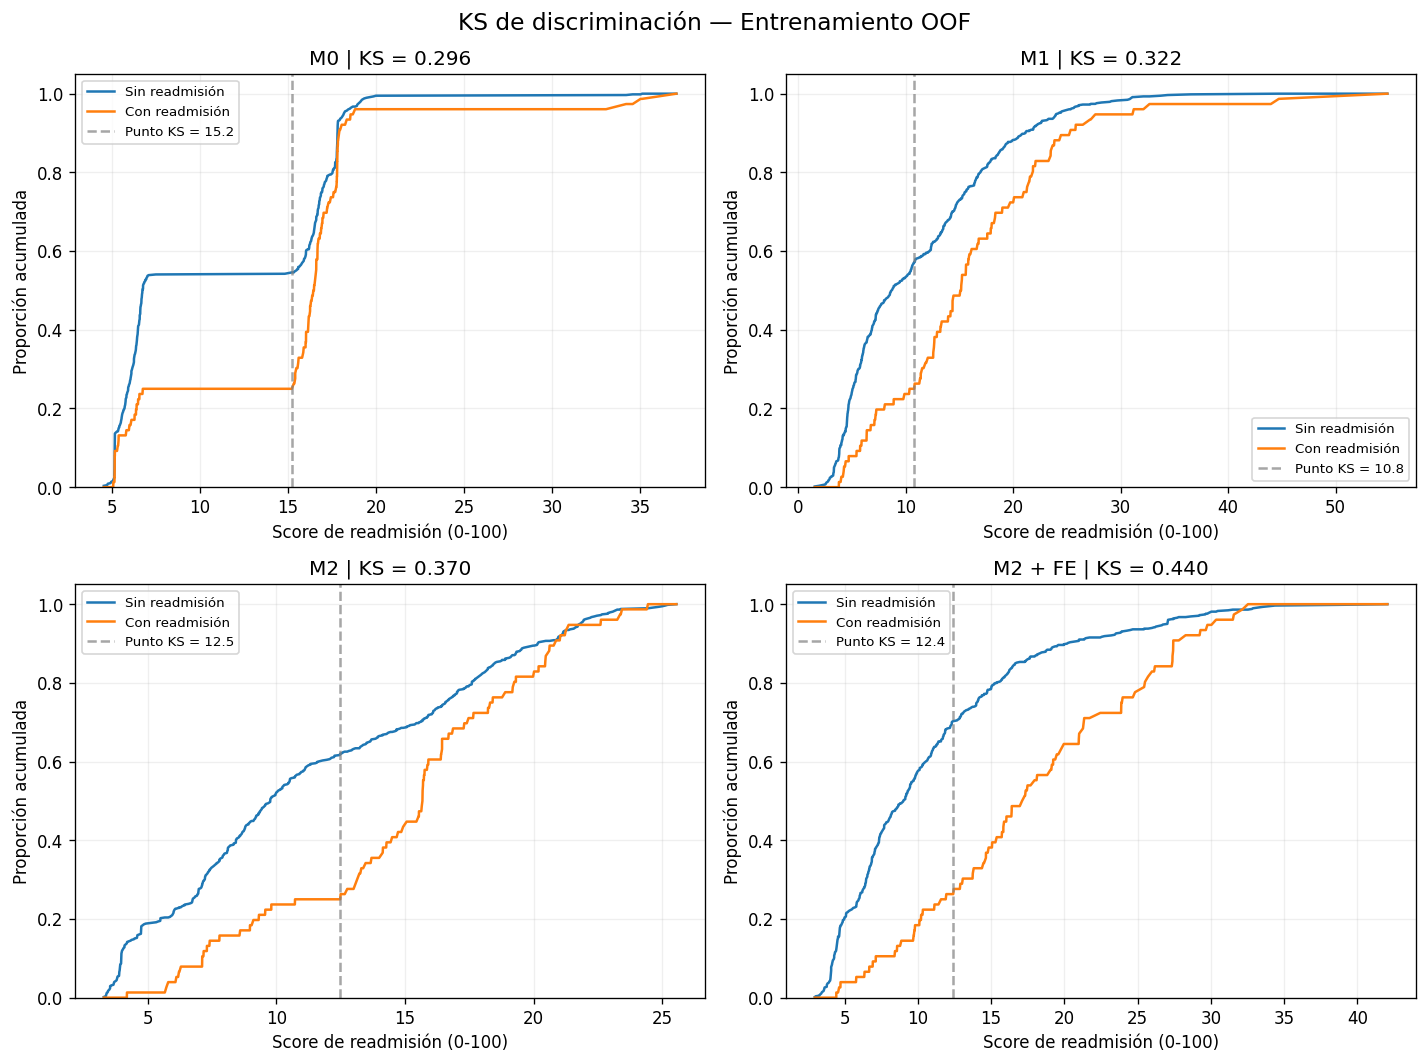

KS Y MÉTRICAS OOF


,Modelo,KS,Punto de máxima separación,AUROC OOF,AUPRC OOF,Brier OOF
0,M0,0.296,0.152,0.611,0.178,0.099
1,M1,0.322,0.108,0.679,0.222,0.098
2,M2,0.370,0.125,0.666,0.172,0.099
3,M2 + FE,0.440,0.124,0.765,0.264,0.094



RIESGO BAJO, MEDIO Y ALTO — ENTRENAMIENTO


,Modelo,Riesgo,Pacientes,Readmisiones,No readmisiones,Readmisión (%),Score medio
0,M0,Bajo,219,14,205,6.39,5.60
1,M0,Medio,218,28,190,12.84,11.20
2,M0,Alto,218,34,184,15.60,18.09
3,M1,Bajo,219,9,210,4.11,4.57
4,M1,Medio,218,25,193,11.47,10.03
5,M1,Alto,218,42,176,19.27,20.29
6,M2,Bajo,219,12,207,5.48,5.43
7,M2,Medio,218,22,196,10.09,10.85
8,M2,Alto,218,42,176,19.27,18.96
9,M2 + FE,Bajo,219,7,212,3.20,5.15



CORTES DE RIESGO FIJADOS


,P33,P67
M0,6.38,16.61
M1,6.19,14.29
M2,7.91,15.41
M2 + FE,7.03,12.96



READMISIÓN REAL Y PREDICCIONES POR GRUPO


,Modelo,Riesgo,Pacientes,Readmisiones,No readmisiones,Readmisión (%),Score medio,Umbral,VP,VN,FP,FN,Aciertos,Errores
0,M0,Bajo,219,14,205,6.39,5.60,0.15,0,205,0,14,205,14
1,M0,Medio,218,28,190,12.84,11.20,0.15,20,113,77,8,133,85
2,M0,Alto,218,34,184,15.60,18.09,0.15,34,0,184,0,34,184
3,M1,Bajo,219,9,210,4.11,4.57,0.12,0,210,0,9,210,9
4,M1,Medio,218,25,193,11.47,10.03,0.12,12,130,63,13,142,76
5,M1,Alto,218,42,176,19.27,20.29,0.12,42,0,176,0,42,176
6,M2,Bajo,219,12,207,5.48,5.43,0.13,0,207,0,12,207,12
7,M2,Medio,218,22,196,10.09,10.85,0.13,12,160,36,10,172,46
8,M2,Alto,218,42,176,19.27,18.96,0.13,42,0,176,0,42,176
9,M2 + FE,Bajo,219,7,212,3.20,5.15,0.13,0,212,0,7,212,7


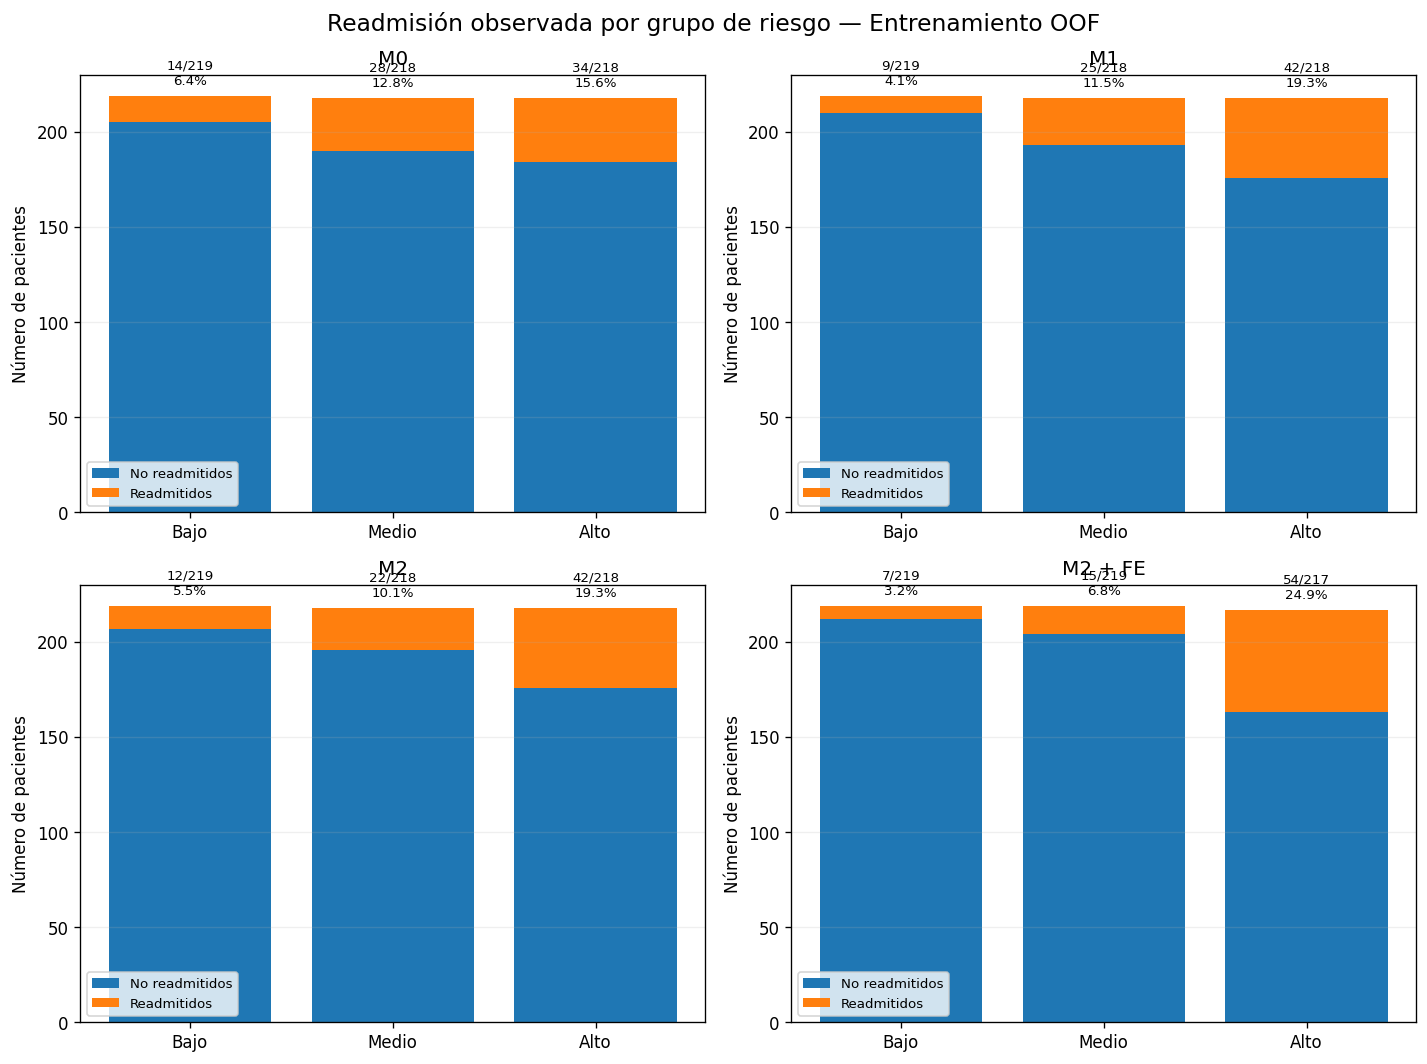

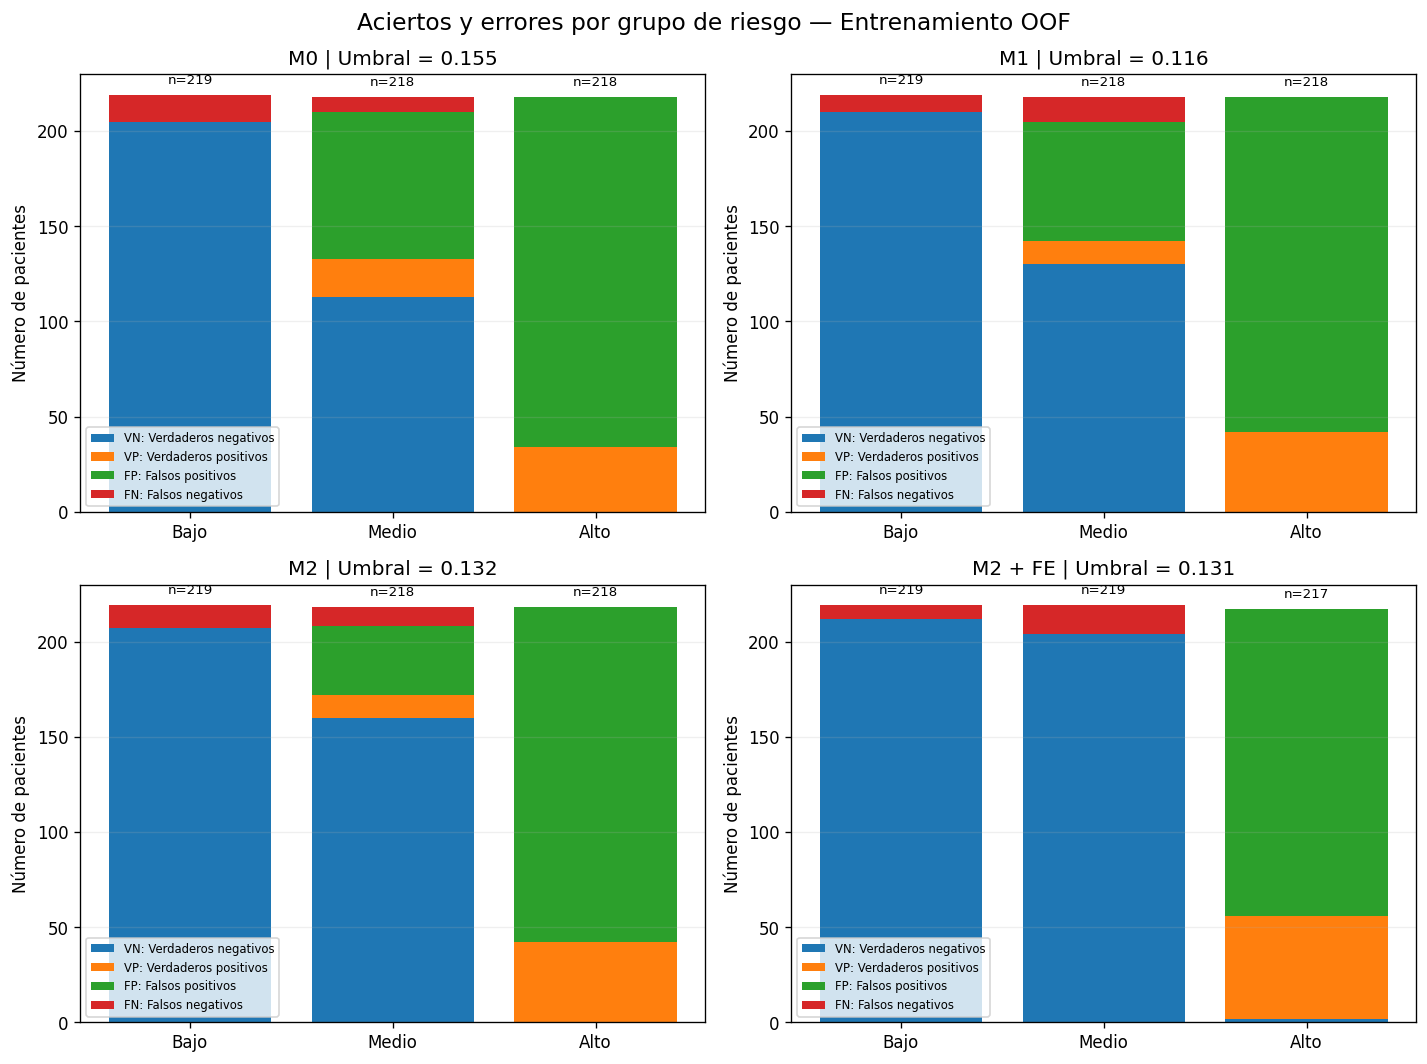

CHECKING COMPLETADO CORRECTAMENTE.
Cada modelo conserva los 655 pacientes de entrenamiento OOF.


In [27]:
# =====================================================
# 16.2. KS Y ESTRATIFICACIÓN DE RIESGO
# ENTRENAMIENTO OOF
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# -----------------------------------------------------
# FUNCIÓN PARA CALCULAR KS
# -----------------------------------------------------


def calcular_curvas_ks(y_real, probabilidades):
    y_real = np.asarray(y_real)
    probabilidades = np.asarray(probabilidades)

    negativos = np.sort(probabilidades[y_real == 0])
    positivos = np.sort(probabilidades[y_real == 1])

    puntos = np.unique(probabilidades)

    f0 = np.searchsorted(negativos, puntos, side="right") / len(negativos)

    f1 = np.searchsorted(positivos, puntos, side="right") / len(positivos)

    diferencia = np.abs(f1 - f0)
    indice = np.argmax(diferencia)

    return {
        "puntos": puntos,
        "F0": f0,
        "F1": f1,
        "KS": float(diferencia[indice]),
        "Punto KS": float(puntos[indice]),
    }


# -----------------------------------------------------
# CURVAS KS DE LOS CUATRO MODELOS
# -----------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=120)

filas_ks = []

for ax, (nombre, probabilidades) in zip(axes.flat, scores_oof.items()):
    probabilidades = np.asarray(probabilidades)

    resultado = calcular_curvas_ks(y_16, probabilidades)

    filas_ks.append(
        {
            "Modelo": nombre,
            "KS": resultado["KS"],
            "Punto de máxima separación": resultado["Punto KS"],
            "AUROC OOF": roc_auc_score(y_16, probabilidades),
            "AUPRC OOF": average_precision_score(y_16, probabilidades),
            "Brier OOF": brier_score_loss(y_16, probabilidades),
        }
    )

    ax.plot(resultado["puntos"] * 100, resultado["F0"], label="Sin readmisión")

    ax.plot(resultado["puntos"] * 100, resultado["F1"], label="Con readmisión")

    ax.axvline(
        resultado["Punto KS"] * 100,
        linestyle="--",
        color="gray",
        alpha=0.7,
        label=f"Punto KS = {resultado['Punto KS'] * 100:.1f}",
    )

    ax.set_title(f"{nombre} | KS = {resultado['KS']:.3f}")
    ax.set_xlabel("Score de readmisión (0-100)")
    ax.set_ylabel("Proporción acumulada")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.suptitle("KS de discriminación — Entrenamiento OOF", fontsize=14)
plt.tight_layout()
plt.show()

tabla_ks_oof = pd.DataFrame(filas_ks)

print("KS Y MÉTRICAS OOF")
display(tabla_ks_oof.round(3))


# -----------------------------------------------------
# DEFINIR TRES GRUPOS DE RIESGO
# CORTES DERIVADOS SOLO DE ENTRENAMIENTO
# -----------------------------------------------------

etiquetas_riesgo = ["Bajo", "Medio", "Alto"]


def asignar_riesgo(probabilidades, cortes):
    return pd.cut(
        probabilidades,
        bins=[-np.inf, cortes[0], cortes[1], np.inf],
        labels=etiquetas_riesgo,
        include_lowest=True,
    )


cortes_riesgo = {}
filas_riesgo = []

for nombre, probabilidades in scores_oof.items():
    probabilidades = np.asarray(probabilidades)

    cortes = np.quantile(probabilidades, [1 / 3, 2 / 3])

    if cortes[0] >= cortes[1]:
        raise ValueError(
            f"{nombre}: no se pueden formar tres grupos "
            "con estos cuantiles debido a scores repetidos."
        )

    cortes_riesgo[nombre] = cortes

    grupos = asignar_riesgo(probabilidades, cortes)

    for grupo in etiquetas_riesgo:
        seleccion = np.asarray(grupos == grupo)
        n = int(seleccion.sum())
        eventos = int(y_16[seleccion].sum())

        filas_riesgo.append(
            {
                "Modelo": nombre,
                "Riesgo": grupo,
                "Pacientes": n,
                "Readmisiones": eventos,
                "No readmisiones": n - eventos,
                "Readmisión (%)": (100 * eventos / n if n else np.nan),
                "Score medio": (
                    100 * probabilidades[seleccion].mean() if n else np.nan
                ),
            }
        )

tabla_riesgo_oof = pd.DataFrame(filas_riesgo)

print("\nRIESGO BAJO, MEDIO Y ALTO — ENTRENAMIENTO")
display(tabla_riesgo_oof.round(2))

print("\nCORTES DE RIESGO FIJADOS")
display(
    pd.DataFrame.from_dict(cortes_riesgo, orient="index", columns=["P33", "P67"])
    .mul(100)
    .round(2)
)


# -----------------------------------------------------
# TABLA DETALLADA:
# READMISIÓN REAL + ACIERTOS/ERRORES POR GRUPO
# -----------------------------------------------------

filas_detalle = []

for nombre, probabilidades in scores_oof.items():
    probabilidades = np.asarray(probabilidades)
    cortes = cortes_riesgo[nombre]

    if nombre not in umbrales_fijados:
        raise KeyError(f"No se encontró un umbral fijado para {nombre}")

    umbral = umbrales_fijados[nombre]

    grupos = np.asarray(asignar_riesgo(probabilidades, cortes).astype(str))

    predicciones = (probabilidades >= umbral).astype(int)

    for grupo in etiquetas_riesgo:
        seleccion = grupos == grupo

        y_real_grupo = np.asarray(y_16)[seleccion]
        y_pred_grupo = predicciones[seleccion]
        scores_grupo = probabilidades[seleccion]

        vp = int(((y_real_grupo == 1) & (y_pred_grupo == 1)).sum())
        vn = int(((y_real_grupo == 0) & (y_pred_grupo == 0)).sum())
        fp = int(((y_real_grupo == 0) & (y_pred_grupo == 1)).sum())
        fn = int(((y_real_grupo == 1) & (y_pred_grupo == 0)).sum())

        n = len(y_real_grupo)
        readmisiones = int(y_real_grupo.sum())
        no_readmisiones = n - readmisiones

        filas_detalle.append(
            {
                "Modelo": nombre,
                "Riesgo": grupo,
                "Pacientes": n,
                "Readmisiones": readmisiones,
                "No readmisiones": no_readmisiones,
                "Readmisión (%)": (100 * readmisiones / n if n else np.nan),
                "Score medio": (100 * scores_grupo.mean() if n else np.nan),
                "Umbral": umbral,
                "VP": vp,
                "VN": vn,
                "FP": fp,
                "FN": fn,
                "Aciertos": vp + vn,
                "Errores": fp + fn,
            }
        )

tabla_detalle_16 = pd.DataFrame(filas_detalle)

print("\nREADMISIÓN REAL Y PREDICCIONES POR GRUPO")
display(tabla_detalle_16.round(2))


# -----------------------------------------------------
# GRÁFICA 1:
# READMISIÓN REAL VS NO READMISIÓN
# -----------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=120)

for ax, nombre in zip(axes.flat, scores_oof.keys()):
    datos = (
        tabla_detalle_16[tabla_detalle_16["Modelo"] == nombre]
        .set_index("Riesgo")
        .reindex(etiquetas_riesgo)
    )

    x = np.arange(len(etiquetas_riesgo))
    no_evento = datos["No readmisiones"].to_numpy()
    evento = datos["Readmisiones"].to_numpy()

    ax.bar(x, no_evento, label="No readmitidos")

    ax.bar(x, evento, bottom=no_evento, label="Readmitidos")

    for i in range(len(etiquetas_riesgo)):
        total = int(datos.iloc[i]["Pacientes"])
        eventos = int(datos.iloc[i]["Readmisiones"])
        tasa = float(datos.iloc[i]["Readmisión (%)"])

        ax.text(
            x[i],
            total + max(1, total * 0.02),
            f"{eventos}/{total}\n{tasa:.1f}%",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x, etiquetas_riesgo)
    ax.set_title(nombre)
    ax.set_ylabel("Número de pacientes")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=8)

plt.suptitle(
    "Readmisión observada por grupo de riesgo — Entrenamiento OOF", fontsize=14
)
plt.tight_layout()
plt.show()


# -----------------------------------------------------
# GRÁFICA 2:
# VP, VN, FP Y FN POR GRUPO DE RIESGO
# -----------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=120)

componentes = [
    ("VN", "Verdaderos negativos"),
    ("VP", "Verdaderos positivos"),
    ("FP", "Falsos positivos"),
    ("FN", "Falsos negativos"),
]

for ax, nombre in zip(axes.flat, scores_oof.keys()):
    datos = (
        tabla_detalle_16[tabla_detalle_16["Modelo"] == nombre]
        .set_index("Riesgo")
        .reindex(etiquetas_riesgo)
    )

    x = np.arange(len(etiquetas_riesgo))
    acumulado = np.zeros(len(etiquetas_riesgo))

    for columna, etiqueta in componentes:
        valores = datos[columna].to_numpy()

        ax.bar(x, valores, bottom=acumulado, label=f"{columna}: {etiqueta}")

        acumulado += valores

    for i in range(len(etiquetas_riesgo)):
        ax.text(
            x[i],
            acumulado[i] + max(1, acumulado[i] * 0.02),
            f"n={int(datos.iloc[i]['Pacientes'])}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x, etiquetas_riesgo)
    ax.set_title(f"{nombre} | Umbral = {umbrales_fijados[nombre]:.3f}")
    ax.set_ylabel("Número de pacientes")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=7)

plt.suptitle("Aciertos y errores por grupo de riesgo — Entrenamiento OOF", fontsize=14)
plt.tight_layout()
plt.show()


# -----------------------------------------------------
# CHECKS FINALES
# -----------------------------------------------------

for nombre in scores_oof.keys():
    datos = tabla_detalle_16[tabla_detalle_16["Modelo"] == nombre]

    assert datos["Pacientes"].sum() == len(y_16)
    assert datos["Readmisiones"].sum() == int(np.sum(y_16))
    assert datos["No readmisiones"].sum() == int(len(y_16) - np.sum(y_16))

print("CHECKING COMPLETADO CORRECTAMENTE.")
print("Cada modelo conserva los 655 pacientes de entrenamiento OOF.")

In [28]:
# =====================================================
# 16.3. PREPARAR LA PRUEBA TEMPORAL
# SIN REAJUSTAR VARIABLES NI UMBRALES
# =====================================================

# Cargar los 165 pacientes posteriores a la fecha de corte
with duckdb.connect(str(db_path), read_only=True) as con:
    test_df = con.execute(
        """
        SELECT *
        FROM results.analytic_dataset
        WHERE index_admission >= ?
        ORDER BY index_admission, person_id
    """,
        [fecha_corte],
    ).df()

assert len(test_df) == 165
assert test_df["readmission_30d"].sum() == 9
assert test_df["person_id"].is_unique
assert set(test_df["person_id"]).isdisjoint(set(train_df["person_id"]))

y_test_16 = test_df["readmission_30d"].astype(int).to_numpy()


# Recuperar registros históricos con el mismo SQL
# utilizado para entrenamiento en la sección 13.

assert "cohorte_train" in consulta

with duckdb.connect(":memory:") as con:
    con.execute(
        f"ATTACH '{str(ruta_omop).replace(chr(39), chr(39) * 2)}' "
        "AS db_omop (READ_ONLY)"
    )

    con.execute(
        f"ATTACH '{str(ruta_raw).replace(chr(39), chr(39) * 2)}' AS db_raw (READ_ONLY)"
    )

    con.register("cohorte_test", test_df[["person_id", "index_admission"]])

    consulta_test = consulta.replace("cohorte_train", "cohorte_test")

    registros_test = con.execute(consulta_test).df()


# Reconstruir exactamente las tres variables de FE
dx_test = registros_test[registros_test["tipo"] == "Diagnóstico"].copy()

dx_test["descripcion"] = dx_test["descripcion"].fillna("").astype(str)

dx_no_onco_test = dx_test[
    ~dx_test["descripcion"].str.contains(patron_cancer, case=False, regex=True)
    & dx_test["descripcion"].str.contains(r"\(disorder\)", case=False, regex=True)
].copy()

med_test = registros_test[registros_test["tipo"] == "Medicamento"].copy()

med_test["descripcion"] = med_test["descripcion"].fillna("").astype(str)

# Construir los cuatro conjuntos de predictores
X_test_16 = {
    "M0": test_df[variables_m0].copy(),
    "M1": test_df[variables_m1].copy(),
    "M2": test_df[variables_m2].copy(),
}

X_test_m2_fe = test_df[variables_m2].copy()

pacientes_cv = dx_no_onco_test.loc[
    dx_no_onco_test["descripcion"].str.contains(
        grupos_diagnosticos["dx_cardiovascular"], case=False, regex=True
    ),
    "person_id",
]

pacientes_antiht = med_test.loc[
    med_test["descripcion"].str.contains(
        grupos_medicamentos["med_antihipertensivos"], case=False, regex=True
    ),
    "person_id",
]

X_test_m2_fe["dx_cardiovascular"] = test_df["person_id"].isin(pacientes_cv).astype(int)

X_test_m2_fe["med_antihipertensivos"] = (
    test_df["person_id"].isin(pacientes_antiht).astype(int)
)

conteo_test = dx_no_onco_test.groupby("person_id")["codigo"].nunique()

X_test_m2_fe[nueva_variable] = (
    test_df["person_id"].map(conteo_test).fillna(0).astype(int)
)

X_test_m2_fe = X_test_m2_fe[variables_m2_fe]

assert list(X_test_m2_fe.columns) == list(X_train_m2_fe.columns)
assert X_test_m2_fe.notna().all().all()

X_test_16["M2 + FE"] = X_test_m2_fe

print("PRUEBA TEMPORAL PREPARADA")
print("Pacientes:", len(test_df))
print("Readmisiones:", int(y_test_16.sum()))
print("Predictores:", {nombre: datos.shape[1] for nombre, datos in X_test_16.items()})

PRUEBA TEMPORAL PREPARADA
Pacientes: 165
Readmisiones: 9
Predictores: {'M0': 3, 'M1': 6, 'M2': 6, 'M2 + FE': 9}


EVALUACIÓN TEMPORAL FINAL


,Modelo,AUROC,AUPRC,Brier,KS discriminación,KS cambio de scores,Umbral fijado,Sensibilidad,Precisión,Especificidad,F2,VP,FP,FN,VN
0,M0,0.736,0.250,0.052,0.498,0.318,0.155,0.778,0.108,0.628,0.347,7,58,2,98
1,M1,0.748,0.223,0.052,0.543,0.098,0.116,0.889,0.119,0.622,0.388,8,59,1,97
2,M2,0.717,0.105,0.053,0.476,0.116,0.132,0.778,0.127,0.692,0.385,7,48,2,108
3,M2 + FE,0.857,0.482,0.046,0.596,0.168,0.131,0.667,0.207,0.853,0.462,6,23,3,133



SCORES INDIVIDUALES DE PRUEBA


,person_id,readmission_30d,Score M0,Riesgo M0,Score M1,Riesgo M1,Score M2,Riesgo M2,Score M2 + FE,Riesgo M2 + FE
0,20082,0,5.86,Bajo,5.28,Bajo,9.870000,Medio,8.55,Medio
1,13423,0,5.82,Bajo,7.03,Medio,11.760000,Medio,8.56,Medio
2,10641,0,5.67,Bajo,3.90,Bajo,3.540000,Bajo,3.69,Bajo
3,1015,1,14.90,Medio,12.77,Medio,7.550000,Bajo,7.32,Medio
4,15069,0,5.90,Bajo,4.55,Bajo,3.430000,Bajo,3.63,Bajo
5,18606,0,5.78,Bajo,11.14,Medio,8.680000,Medio,7.01,Bajo
6,22516,0,5.89,Bajo,14.86,Alto,9.900000,Medio,8.37,Medio
7,16391,1,17.14,Alto,19.89,Alto,20.520000,Alto,10.71,Medio
8,14478,0,5.82,Bajo,5.69,Bajo,8.770000,Medio,7.06,Medio
9,2497,0,5.68,Bajo,3.92,Bajo,3.540000,Bajo,3.69,Bajo



RIESGO BAJO, MEDIO Y ALTO — PRUEBA


,Modelo,Riesgo,Pacientes,Readmisiones,Readmisión (%),Score medio
0,M0,Bajo,96,1,1.04,5.86
1,M0,Medio,4,1,25.00,15.12
2,M0,Alto,65,7,10.77,19.74
3,M1,Bajo,65,1,1.54,4.56
4,M1,Medio,53,3,5.66,10.10
5,M1,Alto,47,5,10.64,21.74
6,M2,Bajo,50,1,2.00,4.79
7,M2,Medio,68,2,2.94,10.23
8,M2,Alto,47,6,12.77,18.55
9,M2 + FE,Bajo,58,0,0.00,5.06


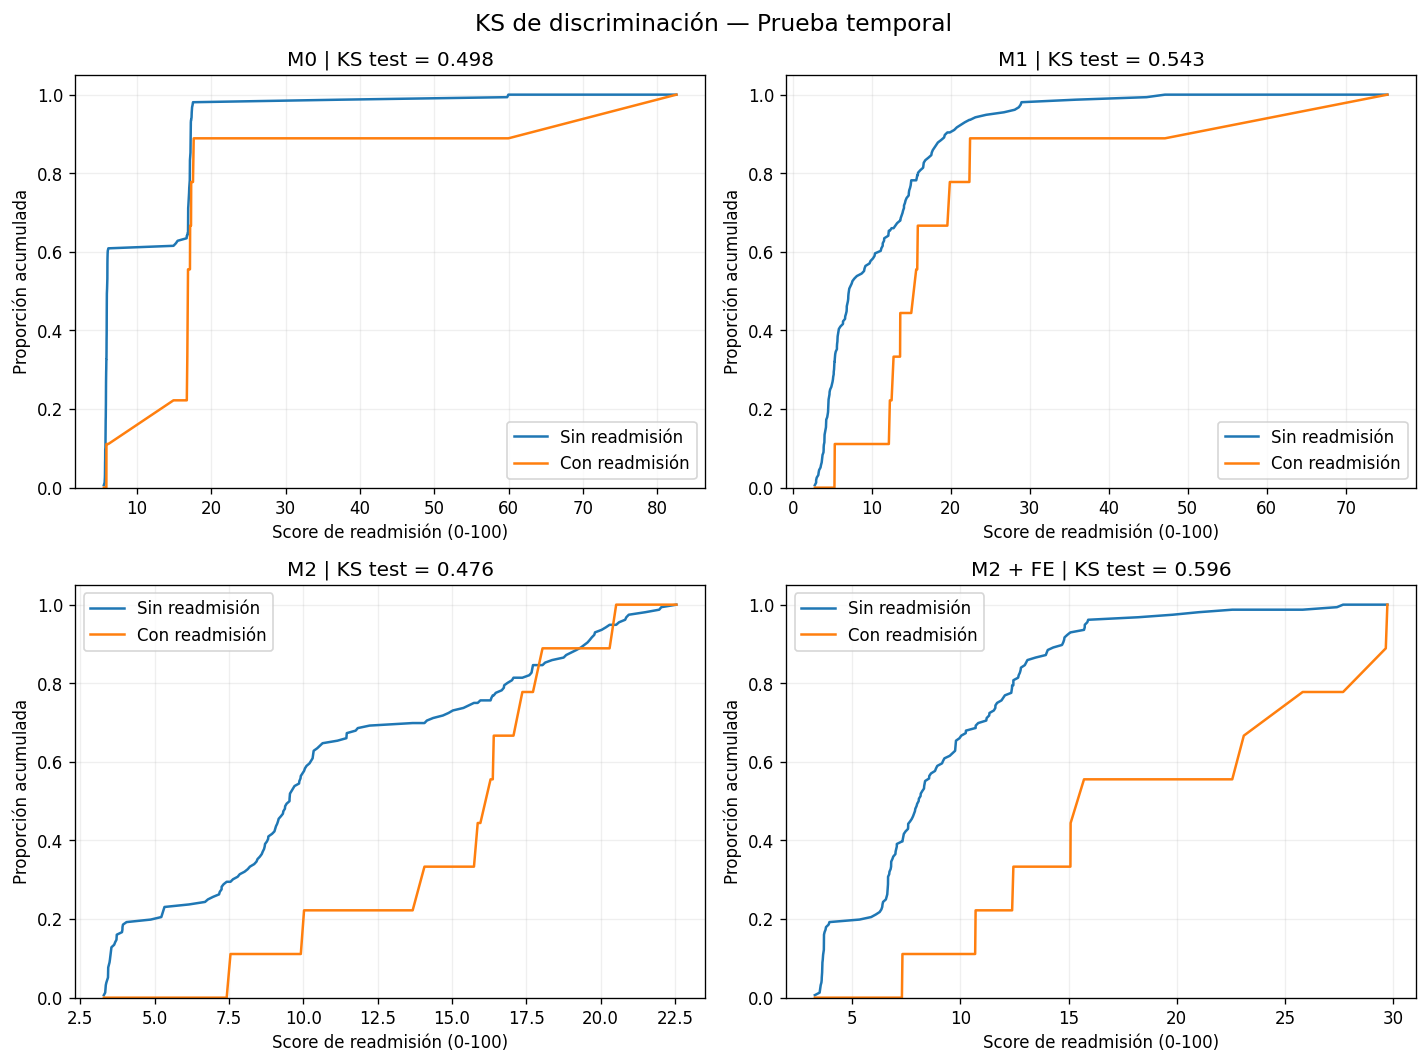

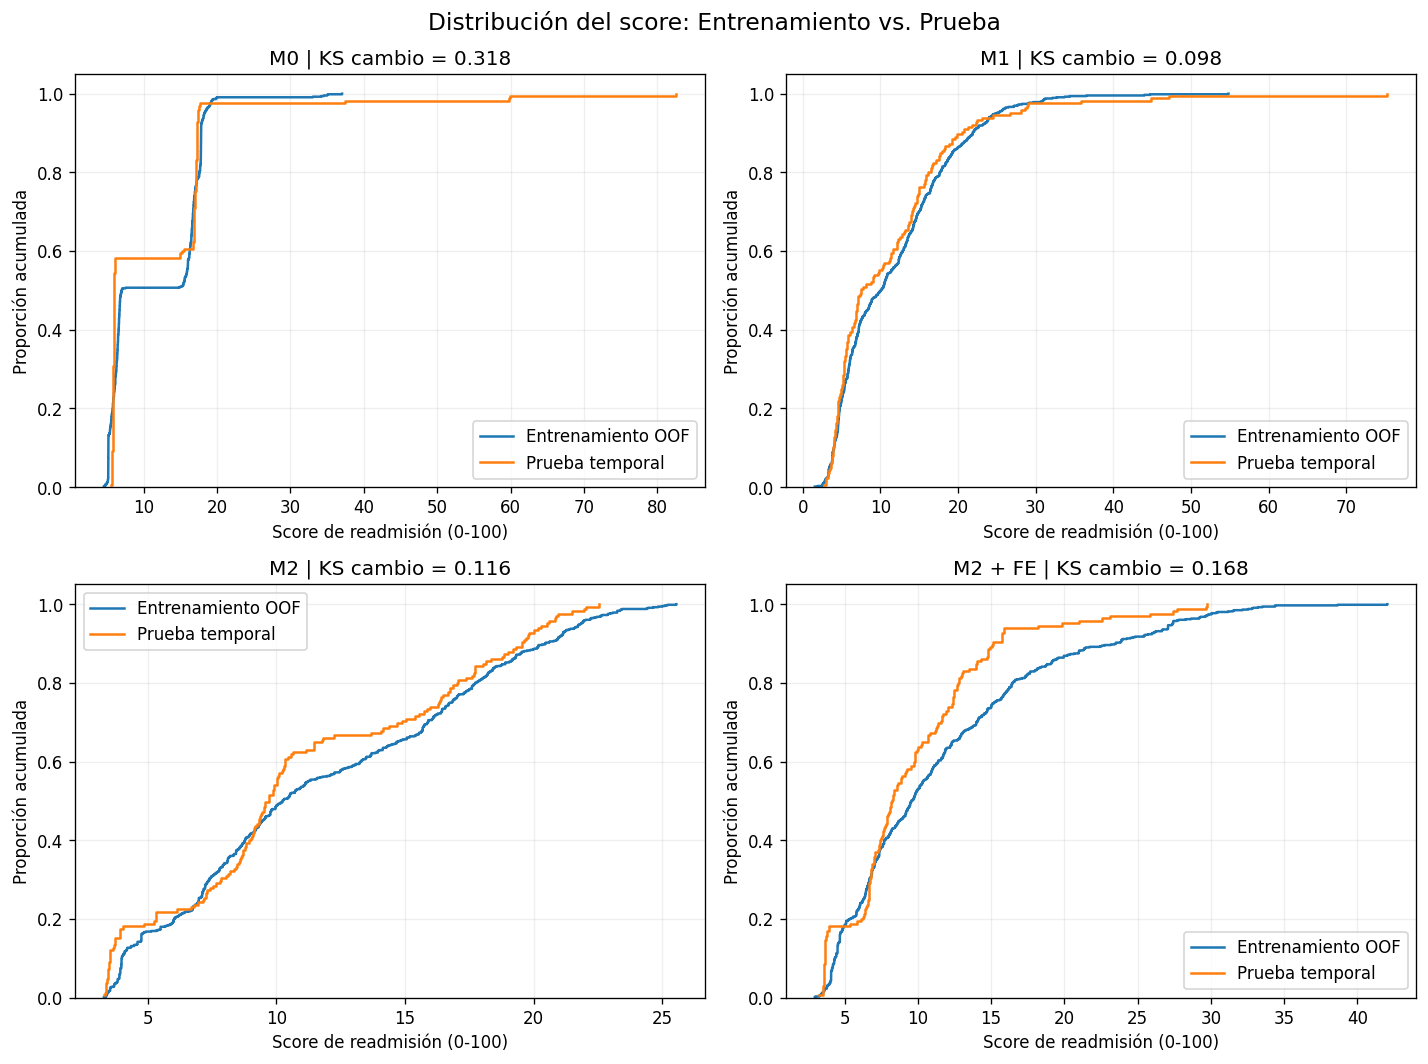

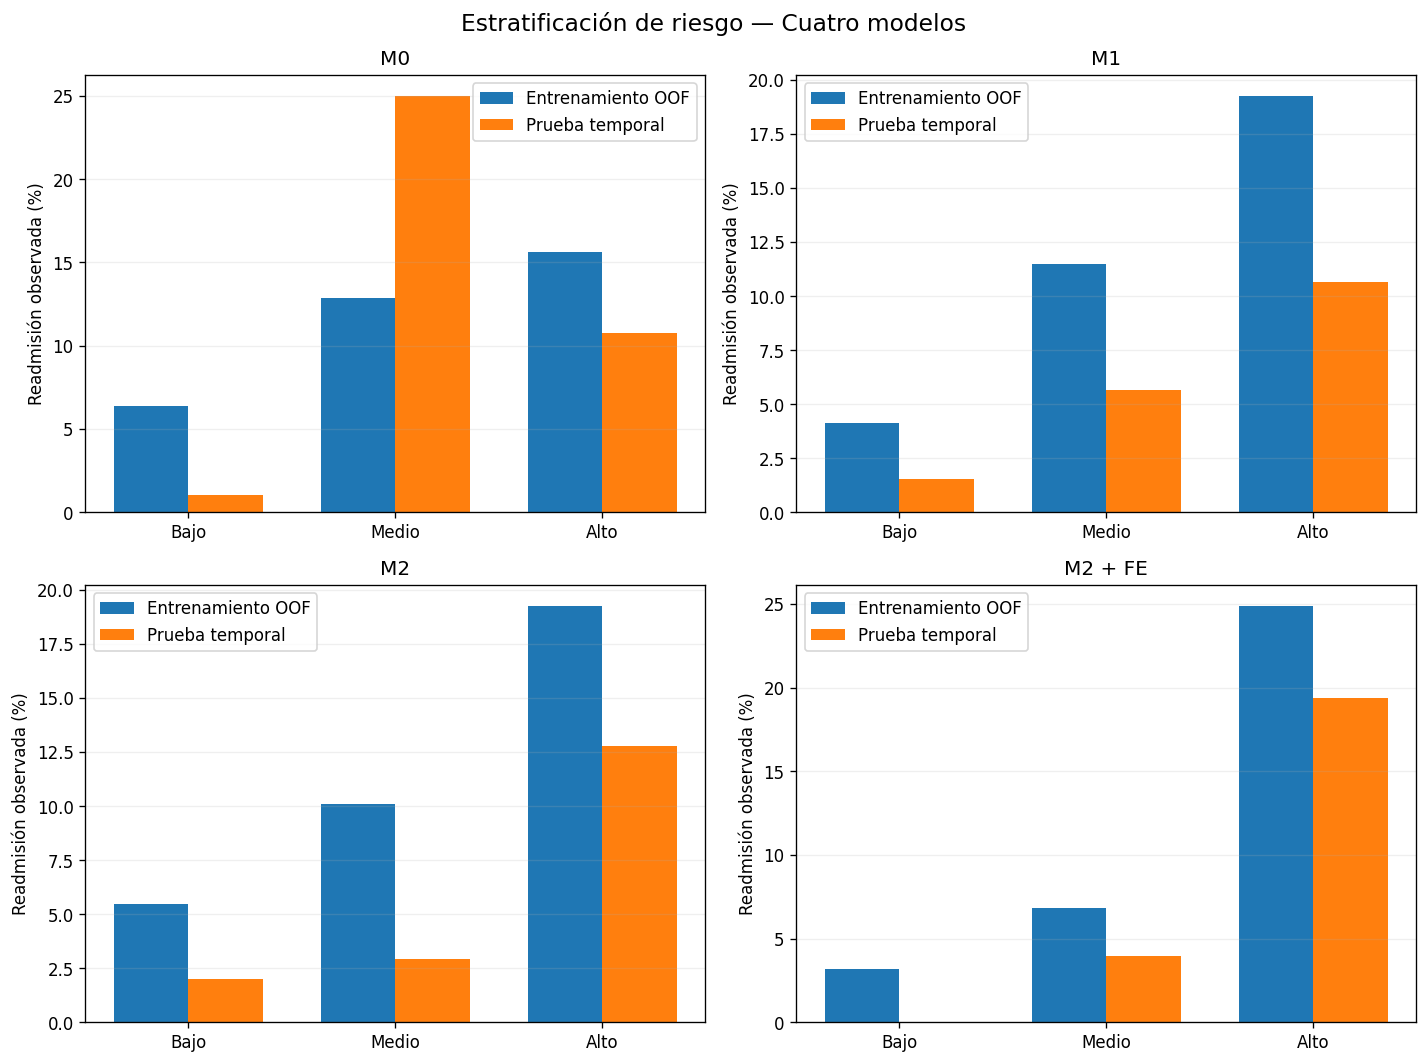

In [29]:
# =====================================================
# 16.4. EVALUACIÓN TEMPORAL FINAL
# SCORES, KS, UMBRALES Y GRUPOS DE RIESGO
# =====================================================

from sklearn.base import clone
from scipy.stats import ks_2samp

scores_test = {}
filas_metricas = []
filas_riesgo_test = []

scores_prueba = pd.DataFrame(
    {"person_id": test_df["person_id"].to_numpy(), "readmission_30d": y_test_16}
)

for nombre, (modelo, X_entrenamiento) in modelos_16.items():
    # Reentrenar exclusivamente en los 655 pacientes
    estimador = clone(modelo)
    estimador.fit(X_entrenamiento, y_train)

    # Aplicar a pacientes posteriores
    probabilidades = estimador.predict_proba(X_test_16[nombre])[:, 1]

    scores_test[nombre] = probabilidades

    # Cortes fijados en entrenamiento
    umbral = umbrales_fijados[nombre]
    cortes = cortes_riesgo[nombre]

    grupos = asignar_riesgo(probabilidades, cortes)

    scores_prueba[f"Score {nombre}"] = probabilidades * 100
    scores_prueba[f"Riesgo {nombre}"] = grupos.astype(str)

    # KS de discriminación en prueba
    ks_prueba = calcular_curvas_ks(y_test_16, probabilidades)["KS"]

    # KS de cambio de distribución de scores
    ks_cambio = ks_2samp(scores_oof[nombre], probabilidades).statistic

    filas_metricas.append(
        {
            "Modelo": nombre,
            "AUROC": roc_auc_score(y_test_16, probabilidades),
            "AUPRC": average_precision_score(y_test_16, probabilidades),
            "Brier": brier_score_loss(y_test_16, probabilidades),
            "KS discriminación": ks_prueba,
            "KS cambio de scores": ks_cambio,
            "Umbral fijado": umbral,
            **evaluar_umbral(y_test_16, probabilidades, umbral),
        }
    )

    for grupo in etiquetas_riesgo:
        seleccion = np.asarray(grupos == grupo)
        n = int(seleccion.sum())
        eventos = int(y_test_16[seleccion].sum())

        filas_riesgo_test.append(
            {
                "Modelo": nombre,
                "Riesgo": grupo,
                "Pacientes": n,
                "Readmisiones": eventos,
                "Readmisión (%)": (100 * eventos / n if n else np.nan),
                "Score medio": (
                    100 * probabilidades[seleccion].mean() if n else np.nan
                ),
            }
        )


tabla_metricas_test = pd.DataFrame(filas_metricas)
tabla_riesgo_test = pd.DataFrame(filas_riesgo_test)

print("EVALUACIÓN TEMPORAL FINAL")
display(tabla_metricas_test.round(3))

print("\nSCORES INDIVIDUALES DE PRUEBA")
display(scores_prueba.head(15).round(2))

print("\nRIESGO BAJO, MEDIO Y ALTO — PRUEBA")
display(tabla_riesgo_test.round(2))


# -----------------------------------------------------
# KS DE DISCRIMINACIÓN EN PRUEBA
# -----------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=120)

for ax, (nombre, probabilidades) in zip(axes.flat, scores_test.items()):
    resultado = calcular_curvas_ks(y_test_16, probabilidades)

    ax.plot(resultado["puntos"] * 100, resultado["F0"], label="Sin readmisión")

    ax.plot(resultado["puntos"] * 100, resultado["F1"], label="Con readmisión")

    ax.set_title(f"{nombre} | KS test = {resultado['KS']:.3f}")

    ax.set_xlabel("Score de readmisión (0-100)")
    ax.set_ylabel("Proporción acumulada")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle("KS de discriminación — Prueba temporal", fontsize=14)
plt.tight_layout()
plt.show()


# -----------------------------------------------------
# COMPARAR DISTRIBUCIONES DE SCORE
# ENTRENAMIENTO OOF VS PRUEBA TEMPORAL
# -----------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=120)

for ax, nombre in zip(axes.flat, modelos_16):
    for periodo, probabilidades in [
        ("Entrenamiento OOF", scores_oof[nombre]),
        ("Prueba temporal", scores_test[nombre]),
    ]:
        valores = np.sort(probabilidades)

        acumulada = np.arange(1, len(valores) + 1) / len(valores)

        ax.step(valores * 100, acumulada, where="post", label=periodo)

    ks_cambio = ks_2samp(scores_oof[nombre], scores_test[nombre]).statistic

    ax.set_title(f"{nombre} | KS cambio = {ks_cambio:.3f}")
    ax.set_xlabel("Score de readmisión (0-100)")
    ax.set_ylabel("Proporción acumulada")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle("Distribución del score: Entrenamiento vs. Prueba", fontsize=14)
plt.tight_layout()
plt.show()


# -----------------------------------------------------
# COMPARAR TASAS DE READMISIÓN POR GRUPO DE RIESGO
# -----------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=120)

x = np.arange(3)

for ax, nombre in zip(axes.flat, modelos_16):
    train_r = (
        tabla_riesgo_oof.query("Modelo == @nombre")
        .set_index("Riesgo")
        .reindex(etiquetas_riesgo)
    )

    test_r = (
        tabla_riesgo_test.query("Modelo == @nombre")
        .set_index("Riesgo")
        .reindex(etiquetas_riesgo)
    )

    ax.bar(x - 0.18, train_r["Readmisión (%)"], width=0.36, label="Entrenamiento OOF")

    ax.bar(x + 0.18, test_r["Readmisión (%)"], width=0.36, label="Prueba temporal")

    ax.set_xticks(x, etiquetas_riesgo)
    ax.set_title(nombre)
    ax.set_ylabel("Readmisión observada (%)")
    ax.grid(axis="y", alpha=0.2)
    ax.legend()

plt.suptitle("Estratificación de riesgo — Cuatro modelos", fontsize=14)
plt.tight_layout()
plt.show()